In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os

os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

In [3]:
import json
from pathlib import Path

import dask
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

from cordex2energy.conversion_energy.tyndp import (
    aggregate_battery_capacities_by_zone,
    apply_battery_dispatch,
    build_tyndp_nuts_mapping,
    build_tyndp_zone_geometries,
    drop_overlapping_zones,
    load_nuts_geodata,
    load_tyndp_demand_profiles,
    build_c2e_name_to_iso2,
    load_tyndp_country_codes,
    load_tyndp_market_profiles,
    load_tyndp_battery_capacities,
    load_tyndp_supply_capacities,
)
from cordex2energy.results.extreme_value import (
    compile_and_compare_periods,
    compute_comprehensive_event_metrics,
    compute_continuous_system_metrics,
    compute_evt_thresholds_for_all_zones,
    calculate_climatological_baseline,
)
from cordex2energy.results.plotting import (
    plot_energy_extreme_metrics_dashboard,
    plot_unmet_demand_overview,
)
from cordex2energy.utils.constants import (
    END_CENTURY_PERIOD,
    MID_CENTURY_PERIOD,
    REFERENCE_PERIOD,
)

sns.set_style("whitegrid", {"grid.color": ".93"})

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/cordex2energy/share/proj failed


In [4]:
paths = json.load(open("../../paths_so4.json"))

path_data_processed = Path(paths["path_data_processed"])
path_data_extremes = path_data_processed / "extremes"
path_data_energy = path_data_processed / "energy"
path_data_energy_europe = path_data_energy / "europe"
path_c2e = path_data_processed / "c2e" / "outputs"
path_tyndp = path_data_extremes / "tyndp"
path_residual_load = path_data_extremes / "residual_load"

# Load data

In [5]:
climate_scenario = "rcp85"
demand_scenario = "DE"
demand_year = 2050  # int — 2019 for REF, 2040/2050 for GA/DE
supply_scenario = "HIGH"
supply_year = 2050  # int — 2030/2040/2050

# Scenario suffix as used by compute_tyndp_projections_extremes.py
# Pattern: {demand_scenario}_{demand_year}_{supply_scenario}_{supply_year}
run_tag = f"{demand_scenario}_{demand_year}_{supply_scenario}_{supply_year}"

In [77]:
# ── Battery dispatch toggle ────────────────────────────────────────────────────
# Set True to apply greedy battery dispatch to residual load before analysis.
# When True, EVT thresholds are calibrated on the dispatched reference period,
# giving a consistent like-for-like comparison between periods.
# Run this cell and cell 27 twice (True / False) to compare results.
USE_BATTERIES = False

# Battery parameters (TYNDP 2024 HIGH 2050 values from sheets 1.5 + 1.6)
BATTERY_DURATION_H = 4.0          # assumed energy/power ratio in hours
BATTERY_ROUNDTRIP_EFF = 0.90      # round-trip efficiency
BATTERY_INITIAL_SOC = 0.50        # starting SoC as fraction of capacity

## TYNDP

In [57]:
# ── Load TYNDP supply capacities ──────────────────────────────────────────────

print("\n── Loading TYNDP supply capacities ──────────────────────────────────────────")
path_supply_excel = (
    path_tyndp / "20231103 - Final Supply Inputs for TYNDP 2024 Scenarios.xlsx"
)
df_tyndp_solar, df_tyndp_wind_onshore, df_tyndp_wind_offshore = (
    load_tyndp_supply_capacities(path_supply_excel)
)
print(f"  Solar:           {len(df_tyndp_solar)} rows")
print(f"  Onshore wind:    {len(df_tyndp_wind_onshore)} rows")
print(f"  Offshore wind:   {len(df_tyndp_wind_offshore)} rows")


── Loading TYNDP supply capacities ──────────────────────────────────────────
  Solar:           57 rows
  Onshore wind:    57 rows
  Offshore wind:   68 rows


In [58]:
# ── Load TYNDP battery storage capacities ─────────────────────────────────────
print("\n── Loading TYNDP battery capacities ─────────────────────────────────────────")
s_battery_country = load_tyndp_battery_capacities(
    path_supply_excel, scenario=supply_scenario, year=supply_year
)
s_battery_zone = aggregate_battery_capacities_by_zone(s_battery_country)
print(f"  Total capacity : {s_battery_zone.sum():.0f} GWh")
for zone, gwh in s_battery_zone.items():
    print(f"    {zone:<25}: {gwh:>8.1f} GWh")


── Loading TYNDP battery capacities ─────────────────────────────────────────
  Total capacity : 1652 GWh
    Nordic                   :     58.0 GWh
    Central_Western          :    769.4 GWh
    Iberian_Peninsula        :     52.7 GWh
    Central_Eastern          :     88.1 GWh
    South_East               :    474.1 GWh
    British_Isles            :    209.8 GWh


In [59]:
# ── Load TYNDP demand metadata and build country code mapping ─────────────────

print("\n── Building country code mapping ────────────────────────────────────────────")
path_demand_excel = (
    path_tyndp / "Demand_Scenarios_TYNDP_2024_After_Public_Consultation.xlsb"
)
tyndp_country_codes = load_tyndp_country_codes(path_demand_excel)
C2E_NAME_TO_ISO2 = build_c2e_name_to_iso2(tyndp_country_codes)
print(f"  {len(tyndp_country_codes)} countries in TYNDP mapping.")


── Building country code mapping ────────────────────────────────────────────
  35 countries in TYNDP mapping.


In [60]:
# ── Load TYNDP demand scenario table ──────────────────────────────────────────

print("\n── Loading TYNDP demand scenario table ──────────────────────────────────────")
df_tyndp_demand = pd.read_excel(
    path_demand_excel,
    sheet_name="3_DEMAND_OUTPUT",
    header=[0, 1],
)
df_tyndp_demand.columns = [
    f"{l2}_{l1}" if str(l2) in ["2019", "2040", "2050"] else l2
    for l1, l2 in df_tyndp_demand.columns
]


── Loading TYNDP demand scenario table ──────────────────────────────────────


In [61]:
# ── Build TYNDP zone → NUTS mapping and zone geometries ───────────────────────

print("\n── Building TYNDP zone geometries ───────────────────────────────────────────")
tyndp_bidding_zones = (
    df_tyndp_solar[["Country"]]
    .copy()
    .rename(columns={"Country": "Bidding Zone"})
    .iloc[:-3]
)
tyndp_bidding_zones["iso2"] = tyndp_bidding_zones["Bidding Zone"].apply(
    lambda x: str(x)[:2]
)
all_zones = sorted(tyndp_bidding_zones["Bidding Zone"].unique())

gdf_nuts1, gdf_nuts2, gdf_uk_nuts1 = load_nuts_geodata(
    path_data_processed / "maps" / "nuts"
)
tyndp_nuts2_mapping, df_tyndp_nuts_mapping = build_tyndp_nuts_mapping(
    all_zones, gdf_nuts2, gdf_uk_nuts1
)
gdf_tyndp_zones = build_tyndp_zone_geometries(
    tyndp_nuts2_mapping, df_tyndp_nuts_mapping, gdf_nuts2, gdf_uk_nuts1
)
gdf_tyndp_zones = drop_overlapping_zones(gdf_tyndp_zones)
print(f"  {len(gdf_tyndp_zones)} zones after dropping overlapping geometries.")


── Building TYNDP zone geometries ───────────────────────────────────────────
Loaded NUTS1 (2024) from cache
Loaded NUTS2 (2024) from cache
Loaded UK NUTS1 (2016) from cache

NUTS1: 115 | NUTS2: 299 | UK NUTS1: 12
  49 zones after dropping overlapping geometries.


In [62]:
path_demand_profiles_dir = path_tyndp / "Demand Profiles"
ds_market_for_targets, ds_prosumer_for_targets = load_tyndp_market_profiles(
    path_demand_profiles_dir, demand_scenario, demand_year
)

In [6]:
ds_baseload = xr.open_dataset(path_tyndp / "baseload" / f"baseload_{demand_scenario}_{demand_year}.nc")

<Axes: xlabel='country'>

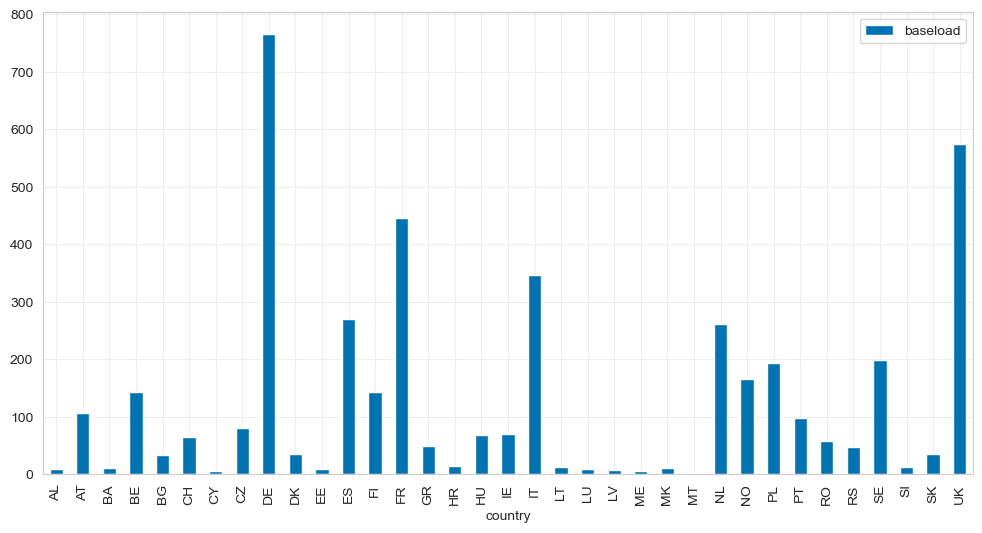

In [12]:
(ds_baseload.sum(dim="hour_of_year").baseload.to_dataframe() * 1e-3).plot(kind="bar", figsize=(12, 6))

## Residual load and components

In [67]:
ds_residual_load = []
ds_residual_load_zonal = []
ds_components = []
ds_components_zonal = []
for folder in sorted(path_residual_load.glob("*")):
    model_name = "_".join(folder.name.split("_")[:-1])
    ds_residual_load.append(
        xr.open_dataset(folder / f"residual_load_{run_tag}.nc").expand_dims(
            dim={"model": [model_name]}
        )
    )
    ds_residual_load_zonal.append(
        xr.open_dataset(folder / f"residual_load_zonal_{run_tag}.nc").expand_dims(
            dim={"model": [model_name]}
        )
    )
    ds_components.append(
        xr.open_dataset(folder / f"components_{run_tag}.nc").expand_dims(
            dim={"model": [model_name]}
        )
    )
    ds_components_zonal.append(
        xr.open_dataset(folder / f"components_zonal_{run_tag}.nc").expand_dims(
            dim={"model": [model_name]}
        )
    )

ds_residual_load = xr.concat(ds_residual_load, dim="model", join="outer")
ds_residual_load_zonal = xr.concat(ds_residual_load_zonal, dim="model", join="outer")
ds_components = xr.concat(ds_components, dim="model", join="outer")
ds_components_zonal = xr.concat(ds_components_zonal, dim="model", join="outer")

# Analysis

The analysis follows the same structure as `extremes.ipynb` but applied to **all model chains simultaneously**.

Inter-model variability is represented using:
- **KDE envelopes**: ensemble median KDE (bold line) with the inter-model 10–90th percentile band (shaded).
- **Spaghetti + IQR**: individual model traces (thin, grey) with the ensemble median (thick, coloured) and an IQR band.
- **Violin plots**: full distribution of model values per period, per zone.
- **Attribution heatmap**: change in climate-driver shares across periods and models.


## Setup — constants, palettes and helpers

In [68]:
from scipy.stats import gaussian_kde

# ── Season / period constants ─────────────────────────────────────────────────
season_map = {
    3: "MAM",
    4: "MAM",
    5: "MAM",
    6: "JJA",
    7: "JJA",
    8: "JJA",
    9: "SON",
    10: "SON",
    11: "SON",
    12: "DJF",
    1: "DJF",
    2: "DJF",
}
season_order = ["DJF", "MAM", "JJA", "SON"]

period_defs = {
    "Reference": (REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]),
    "Mid-Century": (MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1]),
    "End-Century": (END_CENTURY_PERIOD[0], END_CENTURY_PERIOD[1]),
}
# Labels used internally by compile_and_compare_periods
PERIOD_LABEL = {
    "Reference": "1_Reference",
    "Mid-Century": "2_Mid-Century",
    "End-Century": "3_End-Century",
}
PERIOD_SHORT = {v: k for k, v in PERIOD_LABEL.items()}

period_colors = {
    "Reference": "#4A90E2",
    "Mid-Century": "#F5A623",
    "End-Century": "#E24A4A",
}
period_colors_internal = {v: period_colors[k] for k, v in PERIOD_LABEL.items()}

# ── Component / generation palettes ──────────────────────────────────────────
comp_palette = {
    "gen_pv": "#E6AB02",
    "gen_wind_on": "#7570B3",
    "gen_wind_off": "#1B7C3D",
    "gen_hydro_ror": "#3182BD",
    "total_demand": "#D95F02",
}
driver_palette = {
    "Demand": "#D95F02",
    "PV": "#E6AB02",
    "Wind Onshore": "#7570B3",
    "Wind Offshore": "#1B7C3D",
    "Hydro RoR": "#3182BD",
}
driver_cols = {
    "Demand": "Demand_Driven_Share_%",
    "PV": "PV_Driven_Share_%",
    "Wind Onshore": "Wind_Onshore_Driven_Share_%",
    "Wind Offshore": "Wind_Offshore_Driven_Share_%",
    "Hydro RoR": "Hydro_RoR_Driven_Share_%",
}


# ── KDE envelope helper ───────────────────────────────────────────────────────
def _kde_envelope(data_2d, x_grid, bw=0.12):
    """Compute KDE for each model row; return (median, q10, q90) across models.

    Parameters
    ----------
    data_2d : np.ndarray  shape (n_models, n_timesteps)
    x_grid  : np.ndarray  evaluation grid
    bw      : float       KDE bandwidth (Scott-like scalar)

    Returns
    -------
    (median, q10, q90) : each shape (len(x_grid),), or (None, None, None)
    """
    kdes = []
    for row in data_2d:
        pos = row[np.isfinite(row) & (row > 0)]
        if len(pos) < 30:
            continue
        try:
            kdes.append(gaussian_kde(pos, bw_method=bw)(x_grid))
        except Exception:
            pass
    if len(kdes) < 2:
        return None, None, None
    kdes = np.stack(kdes)
    return (
        np.median(kdes, axis=0),
        np.percentile(kdes, 10, axis=0),
        np.percentile(kdes, 90, axis=0),
    )


zones = ds_residual_load_zonal["zone"].values
models = ds_residual_load_zonal["model"].values
n_models = len(models)

print(f"Zones   : {zones}")
print(f"Models  : {n_models}  →  {models}")
print(f"Periods : {list(period_defs.keys())}")

Zones   : ['British_Isles' 'Central_Eastern' 'Central_Western' 'Iberian_Peninsula'
 'Nordic' 'South_East']
Models  : 9  →  ['CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1'
 'CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1'
 'CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1'
 'CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1'
 'MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1'
 'MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1'
 'MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1'
 'MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1'
 'MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1']
Periods : ['Reference', 'Mid-Century', 'End-Century']


## Multi-model KDE by zone and season

One figure per TYNDP balancing zone. Each panel shows one season. For each period the **ensemble
median KDE** is drawn as a bold line; the **10–90th-percentile band across models** is shaded.
The x-axis is shared across periods within a panel so distributional shifts are immediately visible.

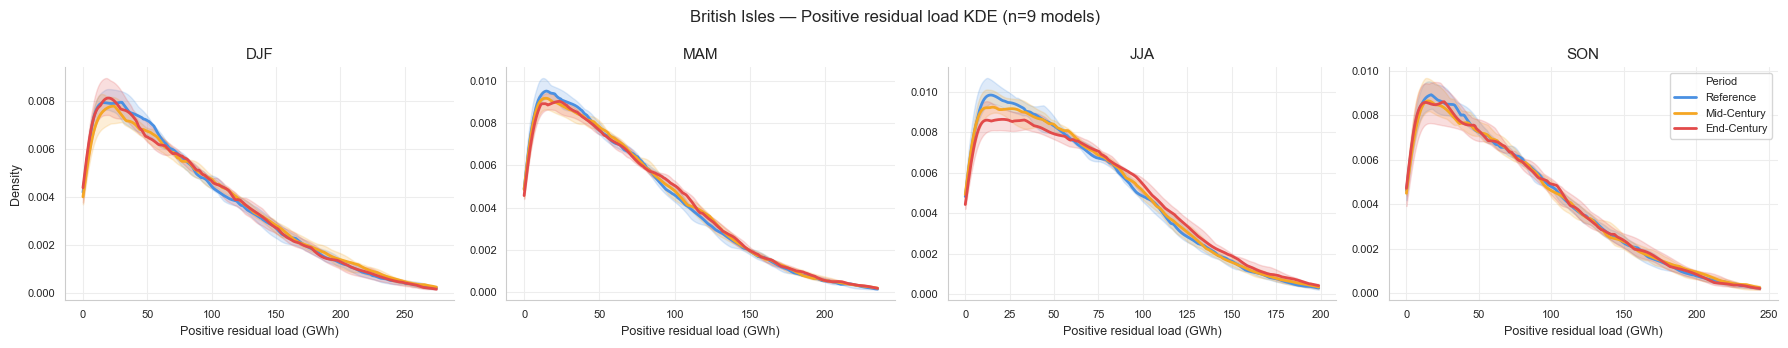

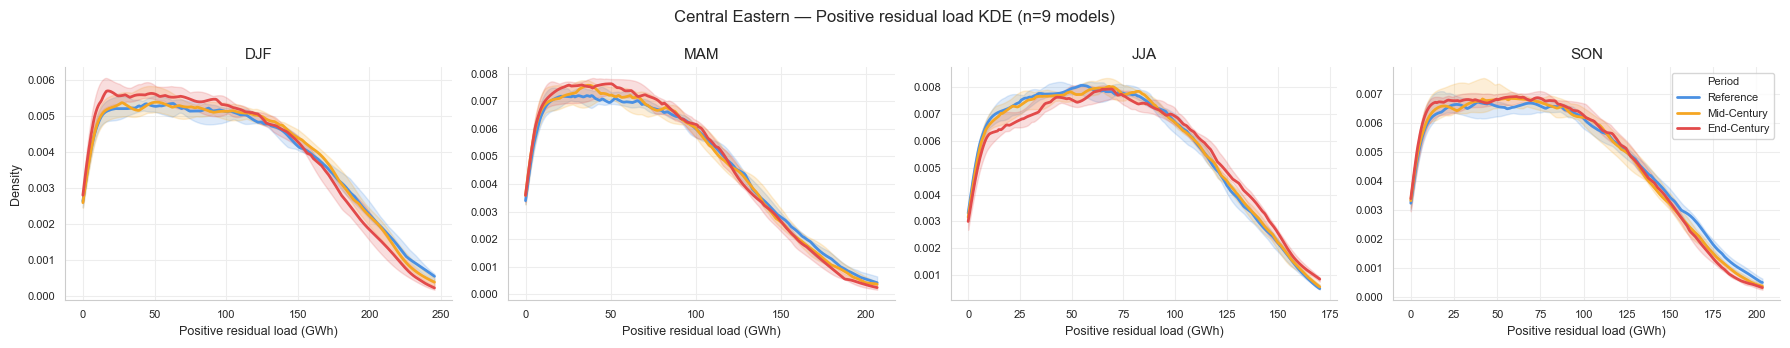

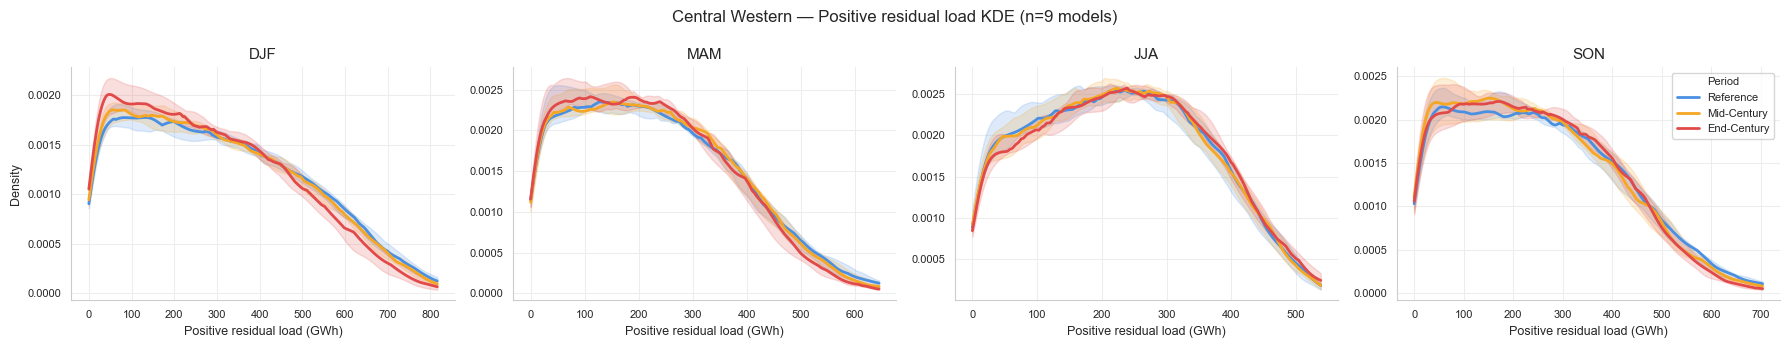

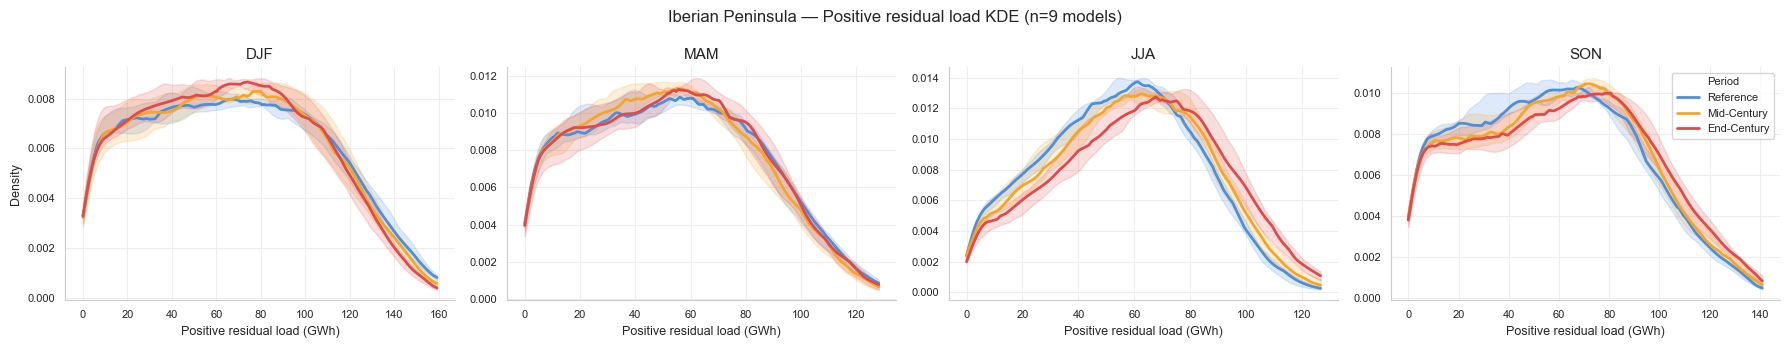

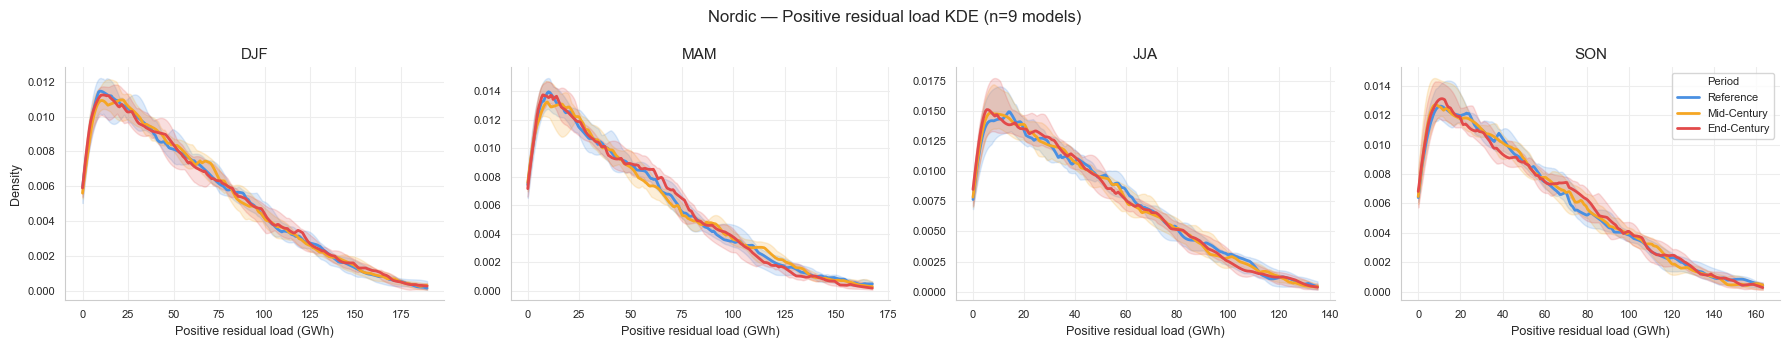

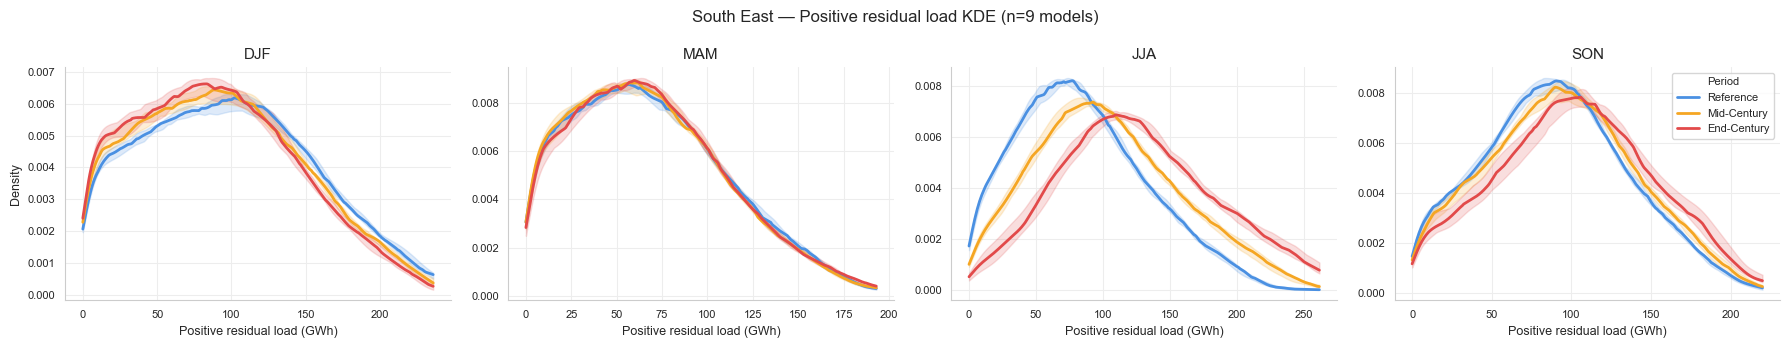

In [69]:
for zone in zones:
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
    fig.suptitle(
        f"{zone.replace('_', ' ')} — Positive residual load KDE (n={n_models} models)",
        fontsize=12,
    )

    for ax, season in zip(axes, season_order):
        # Build a common x-axis spanning all models × all periods
        all_pos = []
        for period_name, (t0, t1) in period_defs.items():
            data = ds_residual_load_zonal.sel(
                zone=zone, time=slice(t0, t1)
            ).residual_load.values
            months = ds_residual_load_zonal.sel(
                zone=zone, time=slice(t0, t1)
            ).time.dt.month.values
            smask = np.array([season_map[m] for m in months]) == season
            chunk = data[:, smask].ravel()
            all_pos.extend(chunk[np.isfinite(chunk) & (chunk > 0)].tolist())

        if len(all_pos) < 50:
            ax.set_title(season, fontsize=11)
            ax.set_visible(False)
            continue

        x_grid = np.linspace(0, np.percentile(all_pos, 99.5), 300)

        for period_name, (t0, t1) in period_defs.items():
            color = period_colors[period_name]
            data = ds_residual_load_zonal.sel(
                zone=zone, time=slice(t0, t1)
            ).residual_load.values
            months = ds_residual_load_zonal.sel(
                zone=zone, time=slice(t0, t1)
            ).time.dt.month.values
            smask = np.array([season_map[m] for m in months]) == season

            med, q10, q90 = _kde_envelope(data[:, smask], x_grid)
            if med is None:
                continue

            ax.fill_between(x_grid, q10, q90, alpha=0.18, color=color)
            ax.plot(x_grid, med, color=color, lw=2, label=period_name)

        ax.set_title(season, fontsize=11)
        ax.set_xlabel("Positive residual load (GWh)", fontsize=9)
        ax.set_ylabel("Density" if season == season_order[0] else "", fontsize=9)
        ax.tick_params(labelsize=8)

    axes[-1].legend(fontsize=8, title="Period", title_fontsize=8)
    sns.despine()
    plt.tight_layout()
    plt.show()

## Per-model EVT thresholds and event metrics

For each model chain:
1. The **EVT threshold** is calibrated on that model's own reference-period residual load (Peaks-Over-Threshold / GPD stability test).
2. **Continuous system metrics** (ramping, PCIT, climate anomalies) are computed for each period using the full-simulation climatological baseline of that model.
3. **Comprehensive event metrics** are computed with both the zero threshold (baseline analysis) and the EVT threshold (extreme-event analysis).

Calibrating thresholds per model avoids conflating a structural bias (model too high/low) with a genuine change in extreme behaviour.

In [78]:
all_df_baseline = []  # list of per-model DataFrames
all_df_extreme = []
evt_thresholds = {}  # {model: da_evt_thresholds}

da_zero_thr = xr.DataArray(
    np.zeros(len(zones)),
    coords={"zone": zones},
    dims=["zone"],
)

for model in models:
    print(f"\n── {model} ──────────────────────────────────────────────────────")

    # Select this model's zonal data from the concatenated ensemble datasets.
    # Drop NaN-padded time steps that arise from the outer-join concat when
    # model time axes do not perfectly overlap.
    ds_rl_m = (
        ds_residual_load_zonal.sel(model=model)
        .drop_vars("model", errors="ignore")
        .dropna("time", how="all")
    )
    ds_comp_m = (
        ds_components_zonal.sel(model=model)
        .drop_vars("model", errors="ignore")
        .dropna("time", how="all")
    )

    # Align to the intersection of both time axes (just in case)
    _common_time = np.intersect1d(ds_rl_m.time.values, ds_comp_m.time.values)
    ds_rl_m = ds_rl_m.sel(time=_common_time)
    ds_comp_m = ds_comp_m.sel(time=_common_time)

    # ── Optional battery dispatch (applied to full simulation for continuity) ──
    if USE_BATTERIES:
        _ds_bat = apply_battery_dispatch(
            ds_rl_m,
            s_battery_zone,
            battery_duration_h=BATTERY_DURATION_H,
            roundtrip_efficiency=BATTERY_ROUNDTRIP_EFF,
            initial_soc_fraction=BATTERY_INITIAL_SOC,
        )
        # Replace residual_load with the dispatched version; drop auxiliary vars
        ds_rl_m = _ds_bat.assign(
            residual_load=_ds_bat["residual_load_with_batteries"]
        ).drop_vars(["residual_load_with_batteries", "soc_gwh"])

    # 1. Climatological baseline — full simulation, used for anomaly computation
    print("  Computing climatological baseline …")
    ds_clim = calculate_climatological_baseline(ds_comp_m.sel(time=slice(*REFERENCE_PERIOD)))

    # 2. Reference-period metrics → EVT threshold
    t0_ref, t1_ref = REFERENCE_PERIOD
    ds_rl_ref = ds_rl_m.sel(time=slice(t0_ref, t1_ref))
    ds_comp_ref = ds_comp_m.sel(time=slice(t0_ref, t1_ref))
    ds_met_ref = compute_continuous_system_metrics(ds_rl_ref, ds_comp_ref, ds_clim)

    print("  Calibrating EVT threshold …")
    da_evt = compute_evt_thresholds_for_all_zones(ds_met_ref["residual_load"])
    evt_thresholds[model] = da_evt
    print(
        "  EVT thresholds (GWh):",
        {str(z): round(float(da_evt.sel(zone=z)), 1) for z in da_evt.zone.values},
    )

    # 3. Compute metrics for all periods
    period_res_baseline = {}
    period_res_extreme = {}

    for period_name, (t0, t1) in period_defs.items():
        print(f"  → {period_name} ({t0}–{t1}) …")
        ds_rl_p = ds_rl_m.sel(time=slice(t0, t1))
        ds_comp_p = ds_comp_m.sel(time=slice(t0, t1))
        ds_met_p = compute_continuous_system_metrics(ds_rl_p, ds_comp_p, ds_clim)

        period_res_baseline[period_name] = compute_comprehensive_event_metrics(
            ds_met_p, da_zero_thr
        )
        period_res_extreme[period_name] = compute_comprehensive_event_metrics(
            ds_met_p, da_evt
        )

    # 4. Compile into period-comparison DataFrames
    df_b, _ = compile_and_compare_periods(
        *[period_res_baseline[k] for k in period_defs]
    )
    df_e, _ = compile_and_compare_periods(*[period_res_extreme[k] for k in period_defs])

    df_b = df_b.reset_index()
    df_e = df_e.reset_index()
    df_b["model"] = model
    df_e["model"] = model

    all_df_baseline.append(df_b)
    all_df_extreme.append(df_e)

df_ens_baseline = pd.concat(all_df_baseline, ignore_index=True)
df_ens_extreme = pd.concat(all_df_extreme, ignore_index=True)

# Rename internal period labels to readable names
df_ens_baseline["Period"] = df_ens_baseline["Period"].map(PERIOD_SHORT)
df_ens_extreme["Period"] = df_ens_extreme["Period"].map(PERIOD_SHORT)

_bat_label = f"with batteries ({s_battery_zone.sum():.0f} GWh)" if USE_BATTERIES else "no batteries"
print(
    f"\n✓ Ensemble DataFrames built: {df_ens_baseline.shape[0]} rows "
    f"({n_models} models × {len(zones)} zones × {len(period_defs)} periods) "
    f"[{_bat_label}]"
)
df_ens_baseline.head(6)


── CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1 ──────────────────────────────────────────────────────
  Computing climatological baseline …
  Calibrating EVT threshold …
  EVT thresholds (GWh): {'British_Isles': 185.7, 'Central_Eastern': 194.5, 'Central_Western': 624.5, 'Iberian_Peninsula': 127.3, 'Nordic': 137.2, 'South_East': 196.5}
  → Reference (1991–2020) …
  → Mid-Century (2036–2065) …
  → End-Century (2071–2100) …

── CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1 ──────────────────────────────────────────────────────
  Computing climatological baseline …
  Calibrating EVT threshold …
  EVT thresholds (GWh): {'British_Isles': 201.6, 'Central_Eastern': 201.1, 'Central_Western': 647.7, 'Iberian_Peninsula': 127.1, 'Nordic': 158.3, 'South_East': 195.8}
  → Reference (1991–2020) …
  → Mid-Century (2036–2065) …
  → End-Century (2071–2100) …

── CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1 ──────────────────────────────────────────────────────
  Computing climatological baseline …
  Calibrating EVT thr

,Zone,Period,Frequency,Avg_Duration_Hours,Max_Duration_Hours,Max_Peak_Intensity_GW,Max_Upward_Ramp_GW_per_hr,Total_Annual_Energy_Severity_GWh,Avg_Energy_Severity_GWh,Max_Single_Event_Severity_GWh,...,Max_PCIT_During_Events_GW,Std_Annual_Energy_Severity_GWh,P90_Annual_Energy_Severity_GWh,CV_Annual_Energy_Severity,Demand_Driven_Share_%,PV_Driven_Share_%,Wind_Onshore_Driven_Share_%,Wind_Offshore_Driven_Share_%,Hydro_RoR_Driven_Share_%,model
0,British_Isles,Reference,4813,12.550384,147.0,335.360157,61.518789,130171.486210,811.374317,19244.751501,...,785.858414,21231.894687,158310.106881,0.163107,7.3,2.6,19.6,70.5,0.0,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1
1,British_Isles,Mid-Century,4771,12.765877,177.0,312.891188,65.643034,133169.370571,837.367662,16724.817785,...,754.531902,20033.368926,160205.085073,0.150435,6.3,2.5,19.6,71.6,0.0,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1
2,British_Isles,End-Century,4626,12.810636,222.0,322.780160,67.565989,133371.414828,836.094040,36119.934844,...,844.726487,22271.980346,161521.984351,0.166992,5.2,2.6,19.7,72.6,0.0,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1
3,Central_Eastern,Reference,7694,14.910320,327.0,293.854596,104.109610,303880.765542,1184.874313,45404.170735,...,707.199559,31196.553413,347086.548056,0.102661,15.4,3.7,31.7,49.3,0.0,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1
4,Central_Eastern,Mid-Century,7599,14.761942,306.0,274.502622,109.346500,293220.604187,1157.602069,38176.405423,...,756.325730,28983.971256,330872.740398,0.098847,12.3,3.5,32.6,51.7,0.0,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1
5,Central_Eastern,End-Century,7401,14.711390,294.0,274.729358,103.438103,293866.852450,1151.484762,35431.671622,...,819.588887,30621.839205,331437.256402,0.104203,11.1,3.6,33.7,51.6,0.0,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1


## Ensemble metric evolution — spaghetti + IQR envelope

Each subplot shows one TYNDP balancing zone. Grey lines are individual model chains; the **coloured
line is the ensemble median**; the **shaded band is the inter-quartile range (Q25–Q75)**.
This is the standard IPCC multi-model representation: the central estimate (median) is shown
together with the spread (IQR), making it easy to assess both the signal and the uncertainty.

Four key operational metrics are shown for the baseline (zero-threshold) analysis.

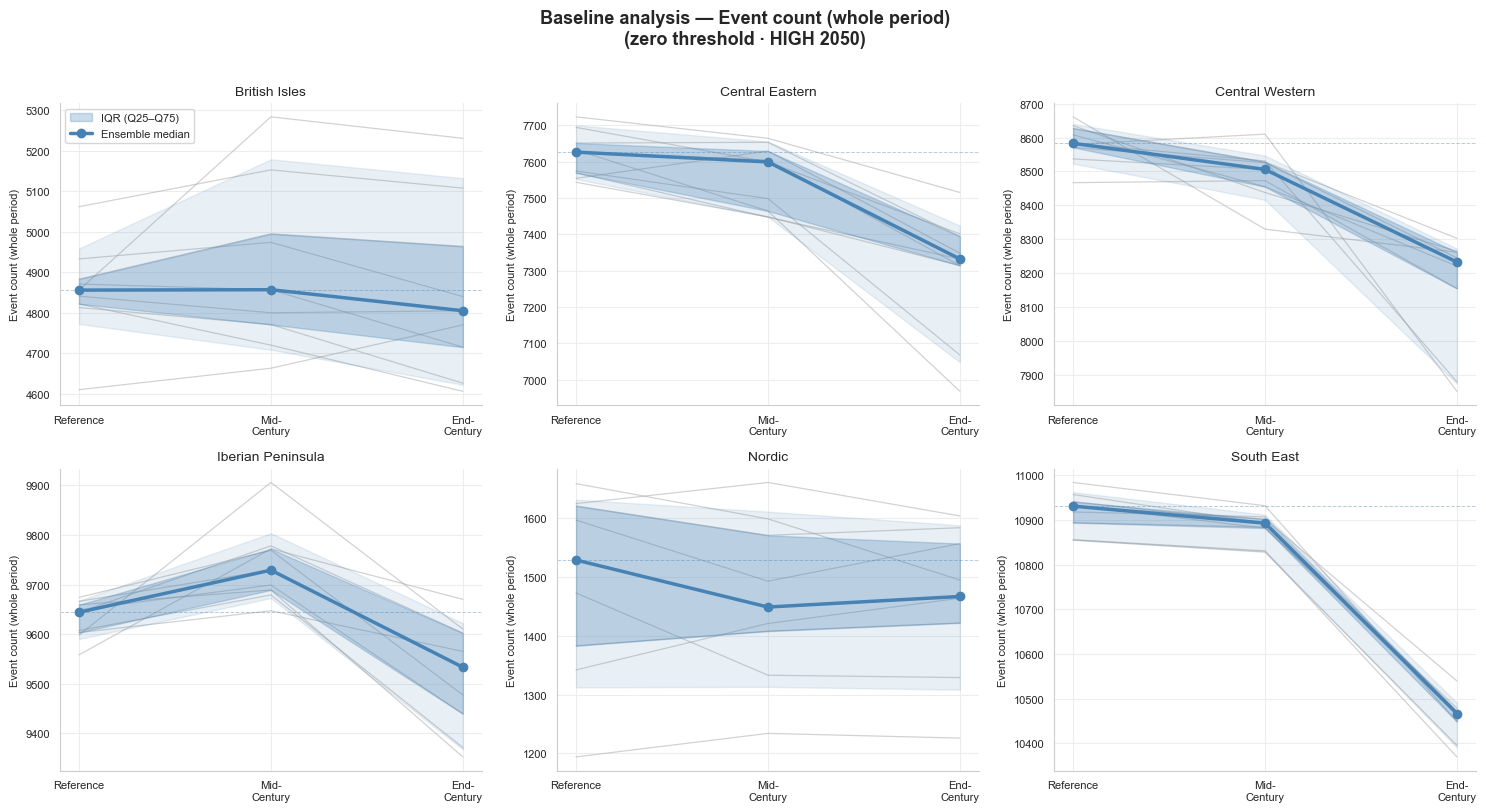

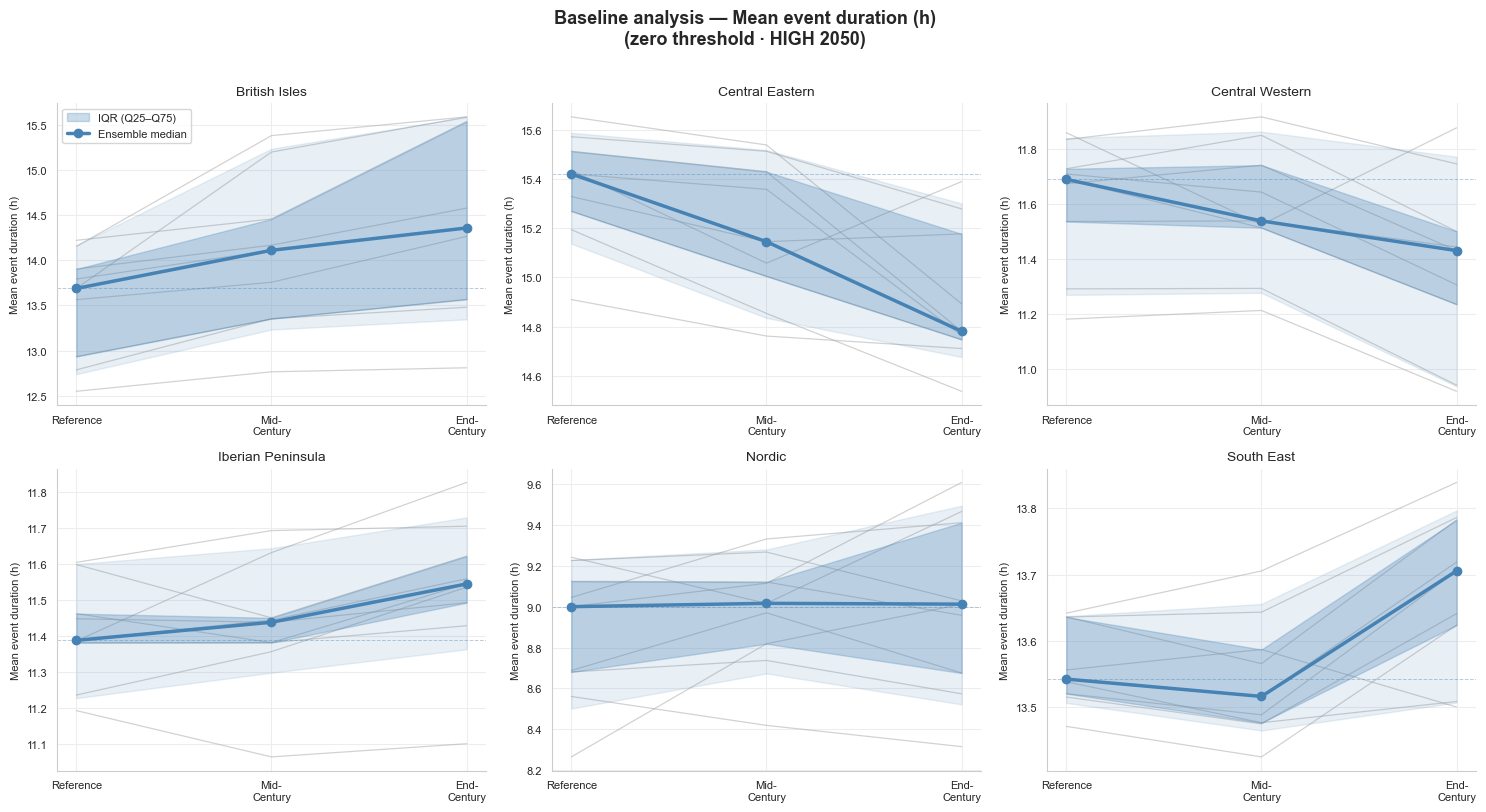

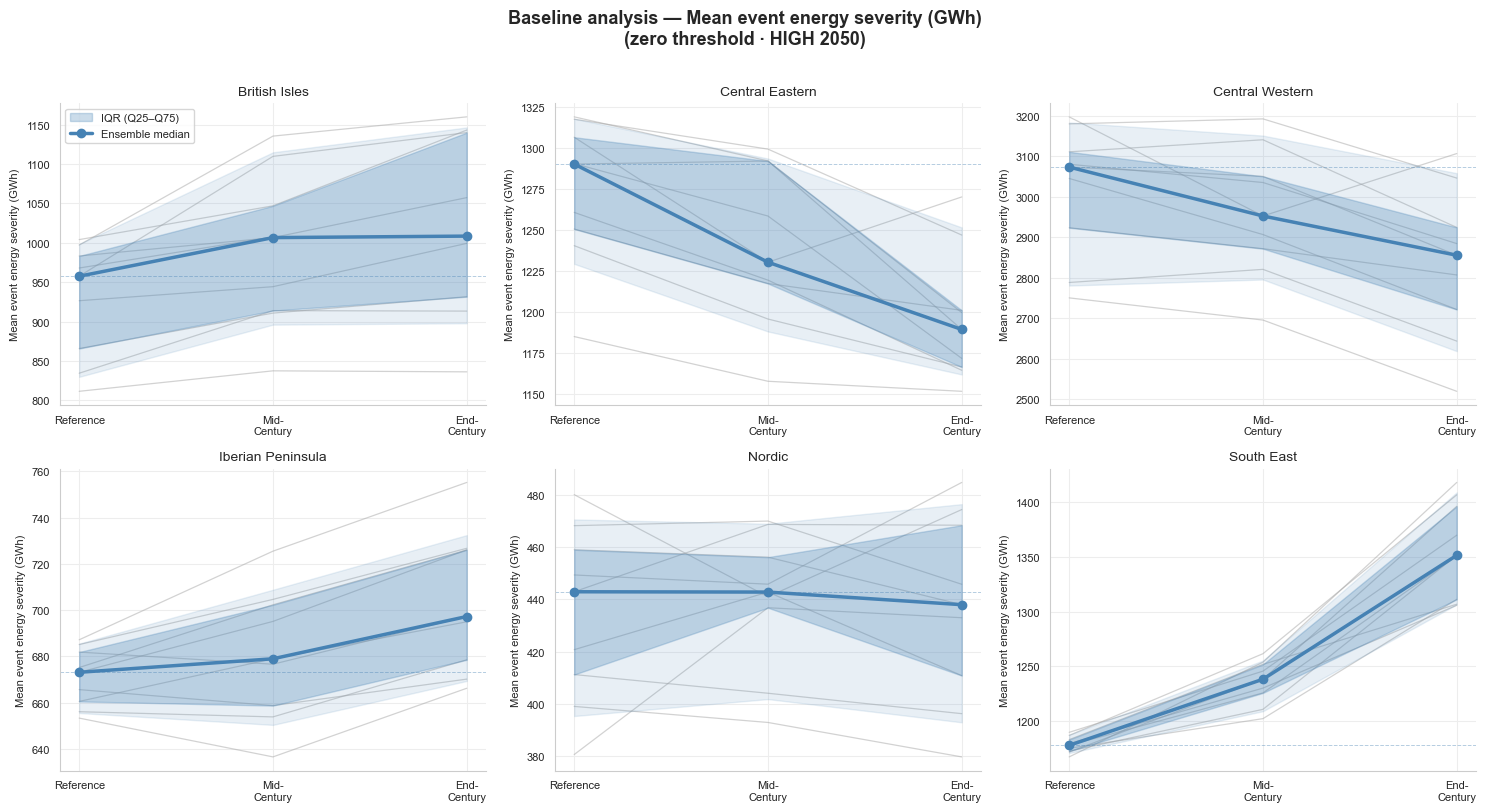

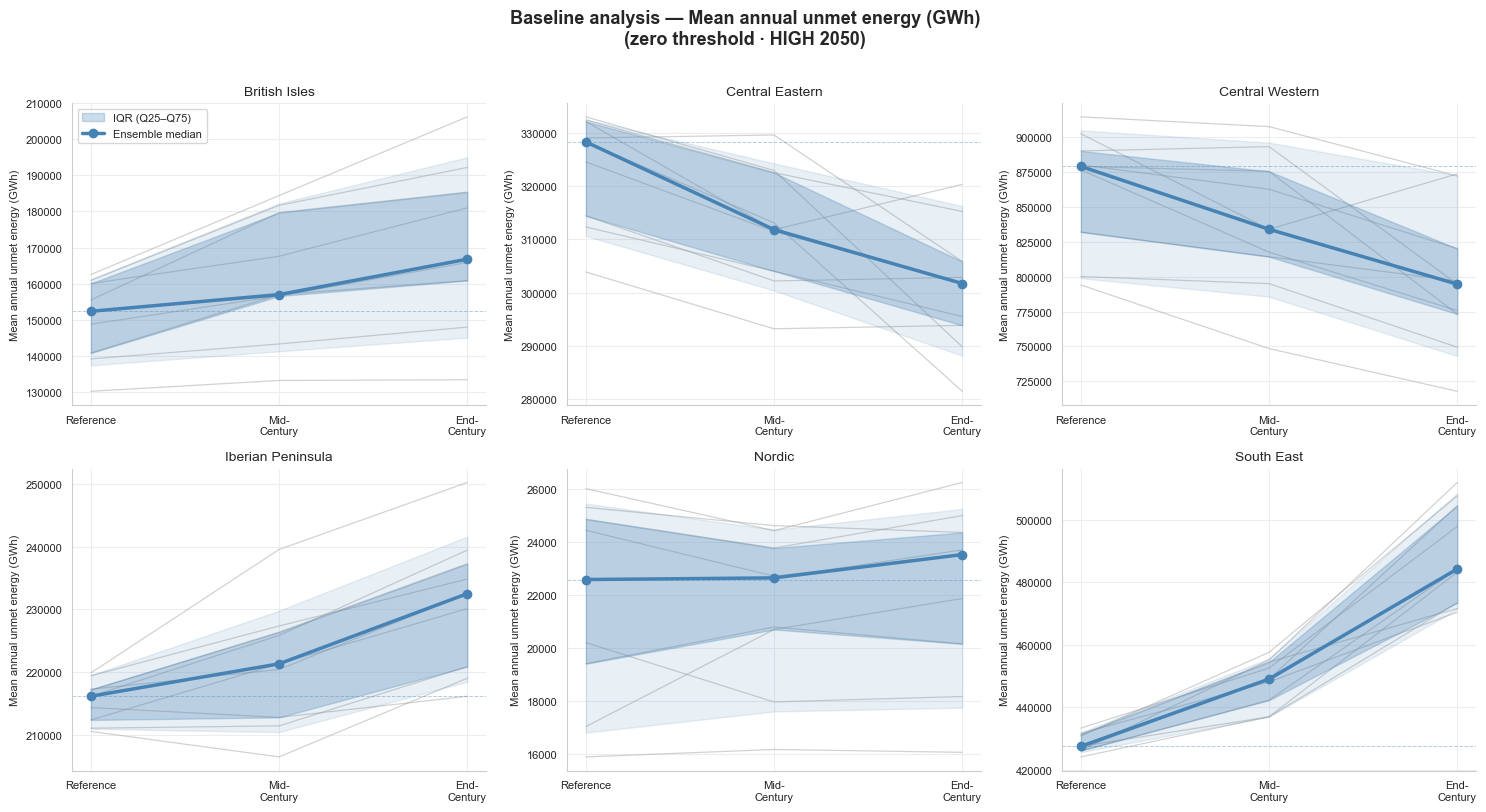

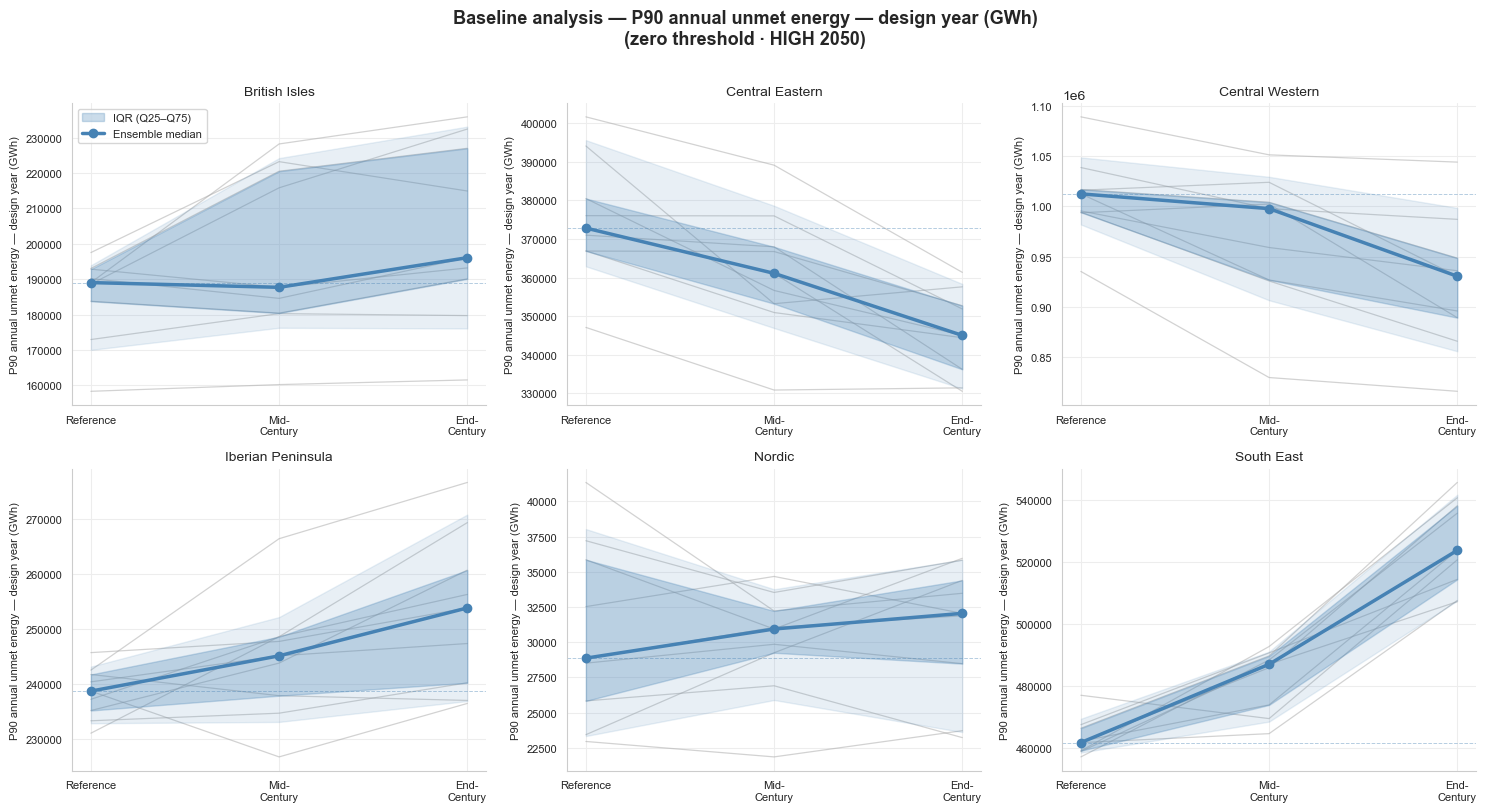

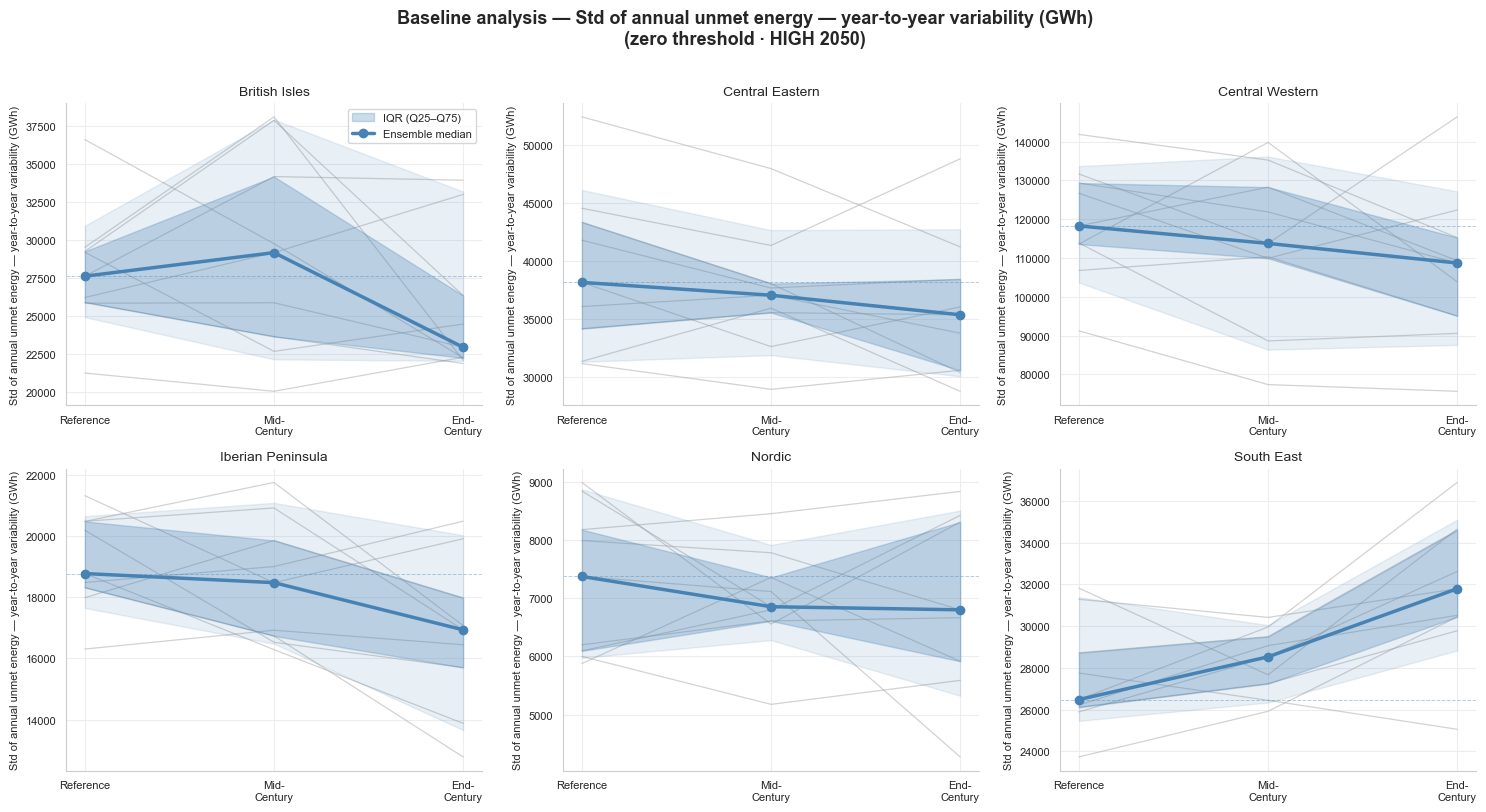

In [ ]:

def _spaghetti_iqr(df_ens, metric, ylabel, title):
    """One 2×3 figure showing metric evolution per zone (spaghetti + IQR).

    Parameters
    ----------
    df_ens   : ensemble DataFrame with columns [Zone, Period, model, *metrics]
    metric   : column name to plot
    ylabel   : y-axis label
    title    : figure title
    """
    period_order = list(period_defs.keys())
    x_pos = {p: i for i, p in enumerate(period_order)}

    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=False)
    axes_flat = axes.flatten()
    fig.suptitle(title, fontsize=13, fontweight="bold", y=1.01)

    for ax, zone in zip(axes_flat, zones):
        df_z = df_ens[df_ens["Zone"] == zone]

        # ── spaghetti (individual models) ─────────────────────────────────────
        for model in models:
            df_zm = df_z[df_z["model"] == model].set_index("Period")
            vals = [
                df_zm.loc[p, metric] if p in df_zm.index else np.nan
                for p in period_order
            ]
            ax.plot(range(3), vals, color="0.65", alpha=0.5, lw=0.9, zorder=1)

        # ── ensemble statistics per period ────────────────────────────────────
        medians, q25s, q75s, q10s, q90s = [], [], [], [], []
        for p in period_order:
            vals = df_z[df_z["Period"] == p][metric].dropna().values
            medians.append(np.median(vals))
            q25s.append(np.percentile(vals, 25))
            q75s.append(np.percentile(vals, 75))
            q10s.append(np.percentile(vals, 10))
            q90s.append(np.percentile(vals, 90))

        x = np.arange(3)
        ax.fill_between(x, q10s, q90s, alpha=0.12, color="steelblue", zorder=2)
        ax.fill_between(
            x, q25s, q75s, alpha=0.28, color="steelblue", zorder=2,
            label="IQR (Q25–Q75)",
        )
        ax.plot(
            x, medians, color="steelblue", lw=2.5, marker="o", ms=6, zorder=3,
            label="Ensemble median",
        )

        # Horizontal reference line at reference-period median
        ax.axhline(medians[0], color="steelblue", lw=0.7, ls="--", alpha=0.4)

        ax.set_xticks([0, 1, 2])
        ax.set_xticklabels(["Reference", "Mid-\nCentury", "End-\nCentury"], fontsize=8)
        ax.set_title(zone.replace("_", " "), fontsize=10)
        ax.set_ylabel(ylabel, fontsize=8)
        ax.tick_params(labelsize=8)
        sns.despine(ax=ax)

    axes_flat[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


# ── Baseline analysis (zero threshold) ───────────────────────────────────────
baseline_metrics = [
    ("Frequency",                        "Event count (whole period)"),
    ("Avg_Duration_Hours",               "Mean event duration (h)"),
    ("Avg_Energy_Severity_GWh",          "Mean event energy severity (GWh)"),
    ("Total_Annual_Energy_Severity_GWh", "Mean annual unmet energy (GWh)"),
    ("P90_Annual_Energy_Severity_GWh",   "P90 annual unmet energy — design year (GWh)"),
    ("Std_Annual_Energy_Severity_GWh",   "Std of annual unmet energy — year-to-year variability (GWh)"),
]

for metric, ylabel in baseline_metrics:
    _spaghetti_iqr(
        df_ens_baseline,
        metric,
        ylabel,
        title=f"Baseline analysis — {ylabel}\n(zero threshold · {supply_scenario} {supply_year})",
    )


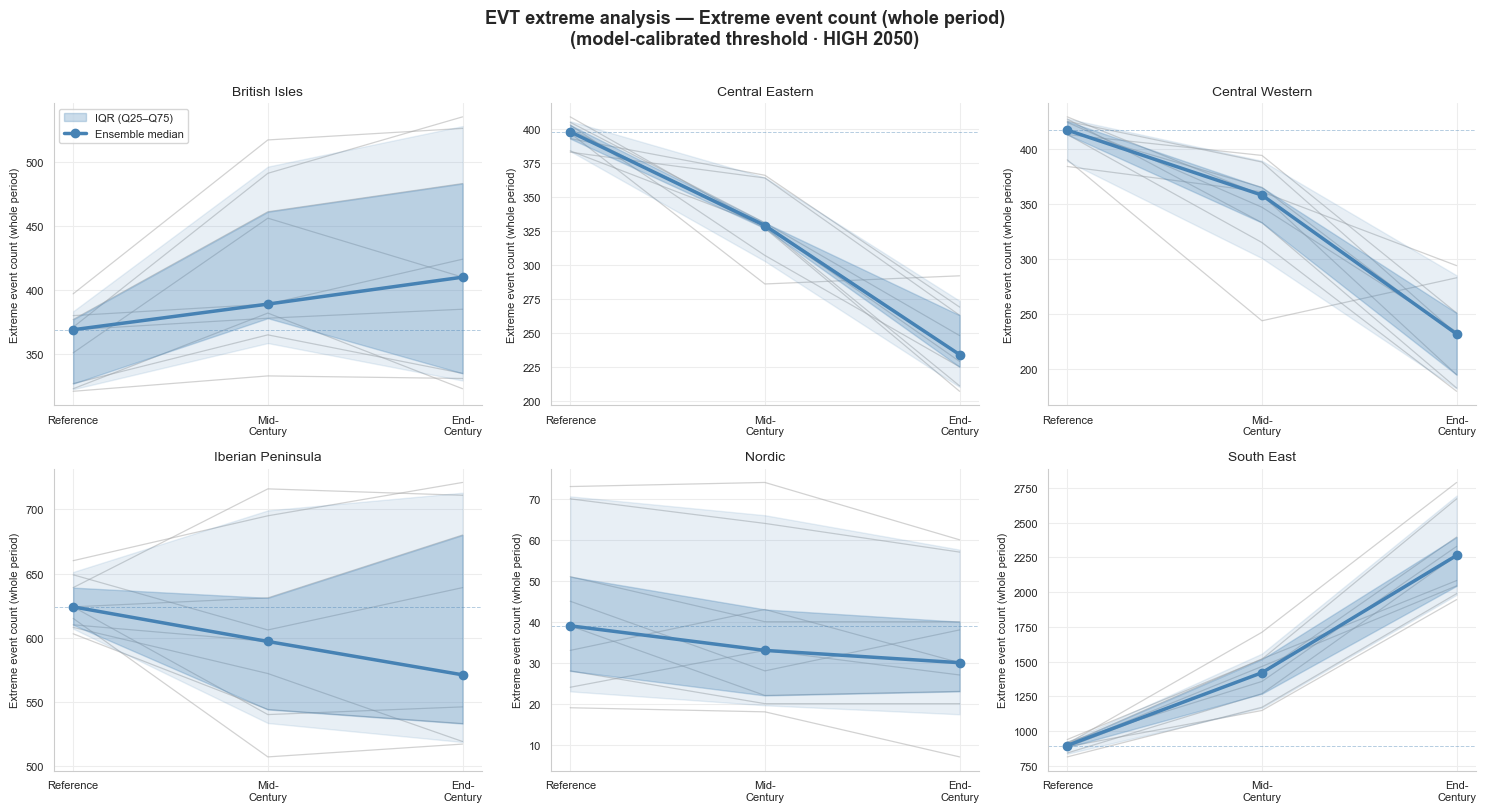

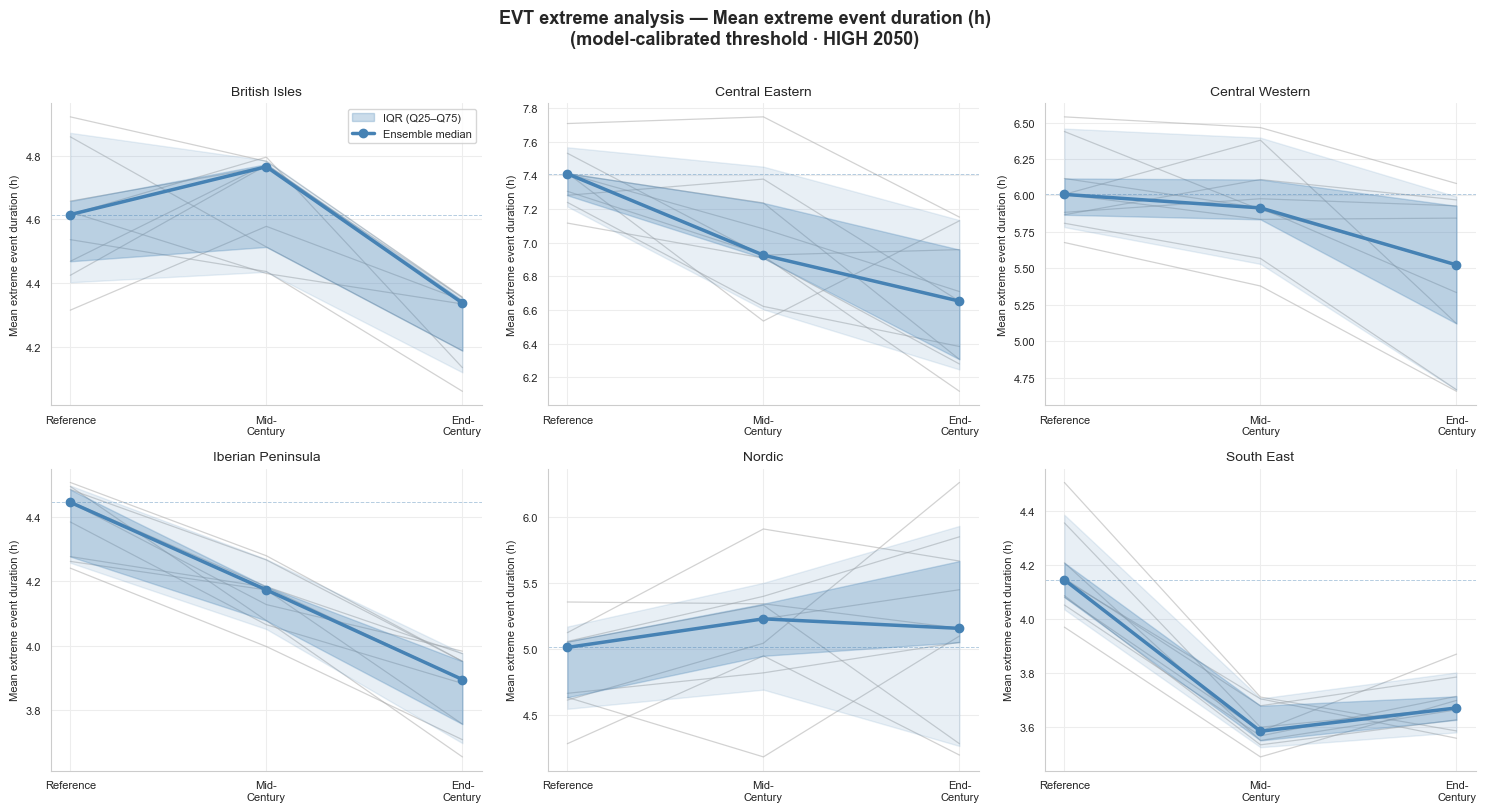

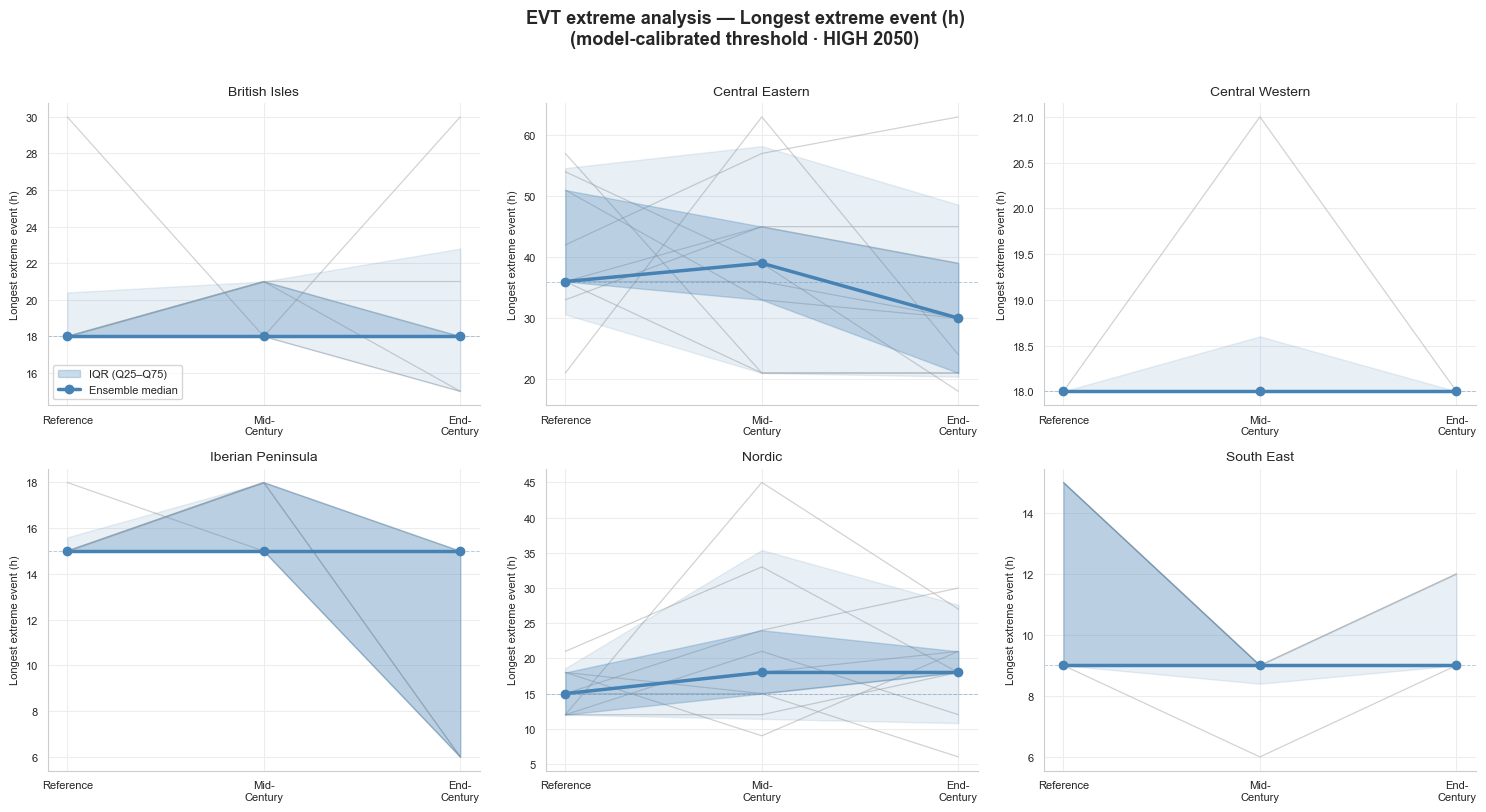

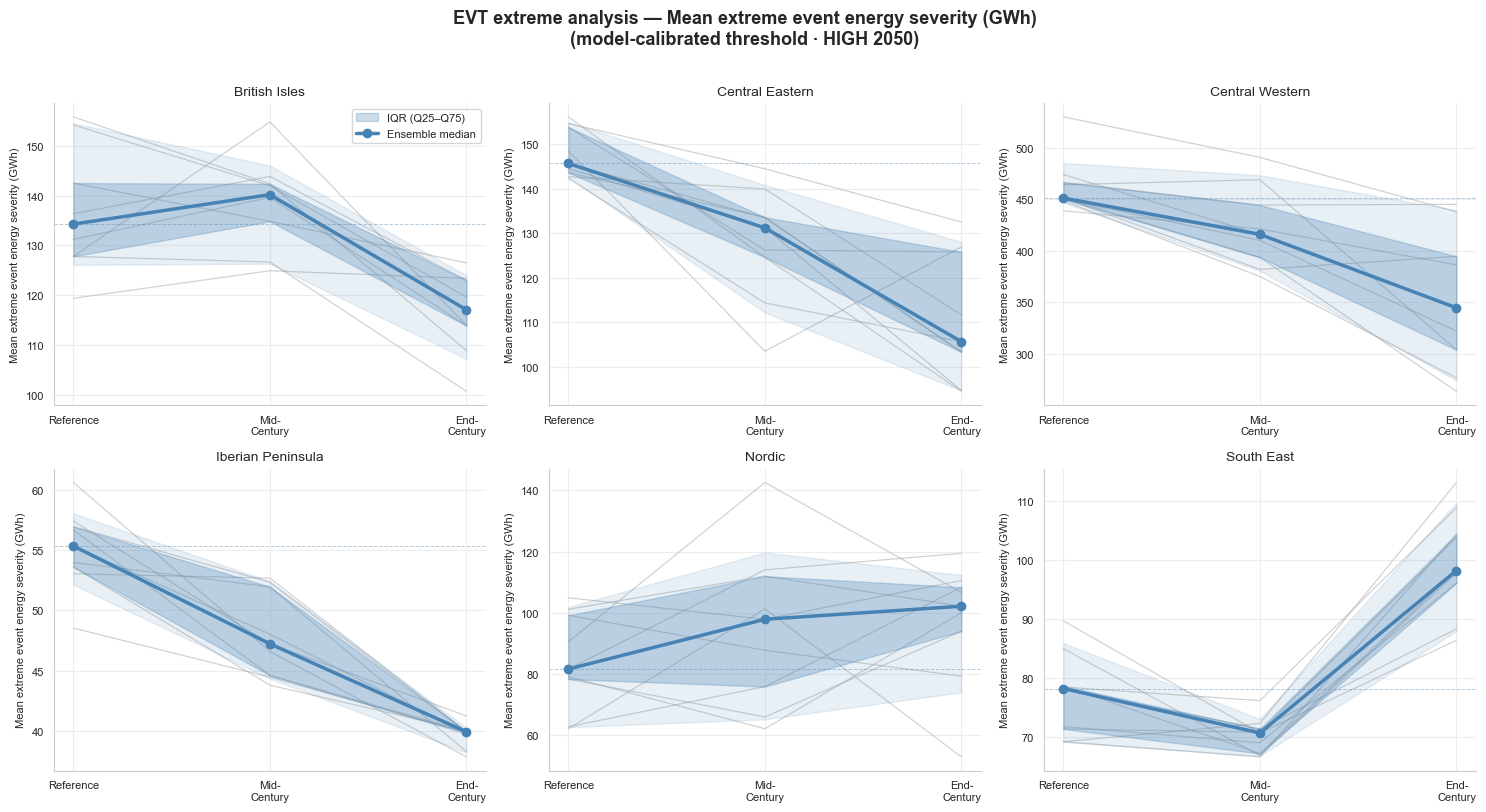

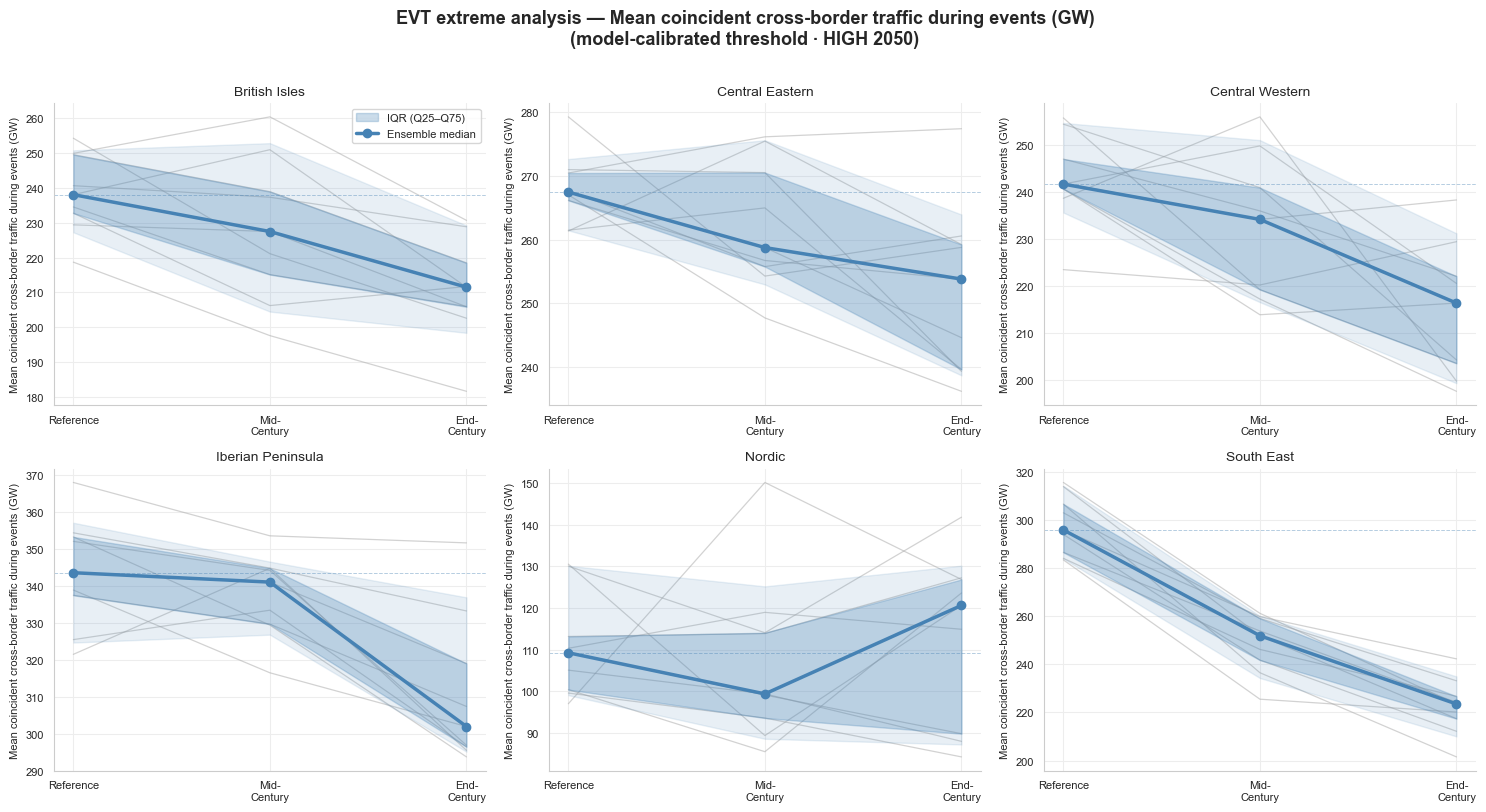

In [80]:
# ── EVT extreme analysis (model-specific threshold) ──────────────────────────
extreme_metrics = [
    ("Frequency", "Extreme event count (whole period)"),
    ("Avg_Duration_Hours", "Mean extreme event duration (h)"),
    ("Max_Duration_Hours", "Longest extreme event (h)"),
    ("Avg_Energy_Severity_GWh", "Mean extreme event energy severity (GWh)"),
    (
        "Avg_PCIT_During_Events_GW",
        "Mean coincident cross-border traffic during events (GW)",
    ),
]

for metric, ylabel in extreme_metrics:
    _spaghetti_iqr(
        df_ens_extreme,
        metric,
        ylabel,
        title=f"EVT extreme analysis — {ylabel}\n(model-calibrated threshold · {supply_scenario} {supply_year})",
    )

## Violin plots — inter-model metric distributions by period

Violin plots show the **full distribution of model values** for each period.
Wider violins indicate more models clustered there; the inner box shows the IQR;
the white dot marks the ensemble median.
This view makes it easy to see whether all models agree on the sign of the change
(robust signal) or whether there is model disagreement (uncertain signal).

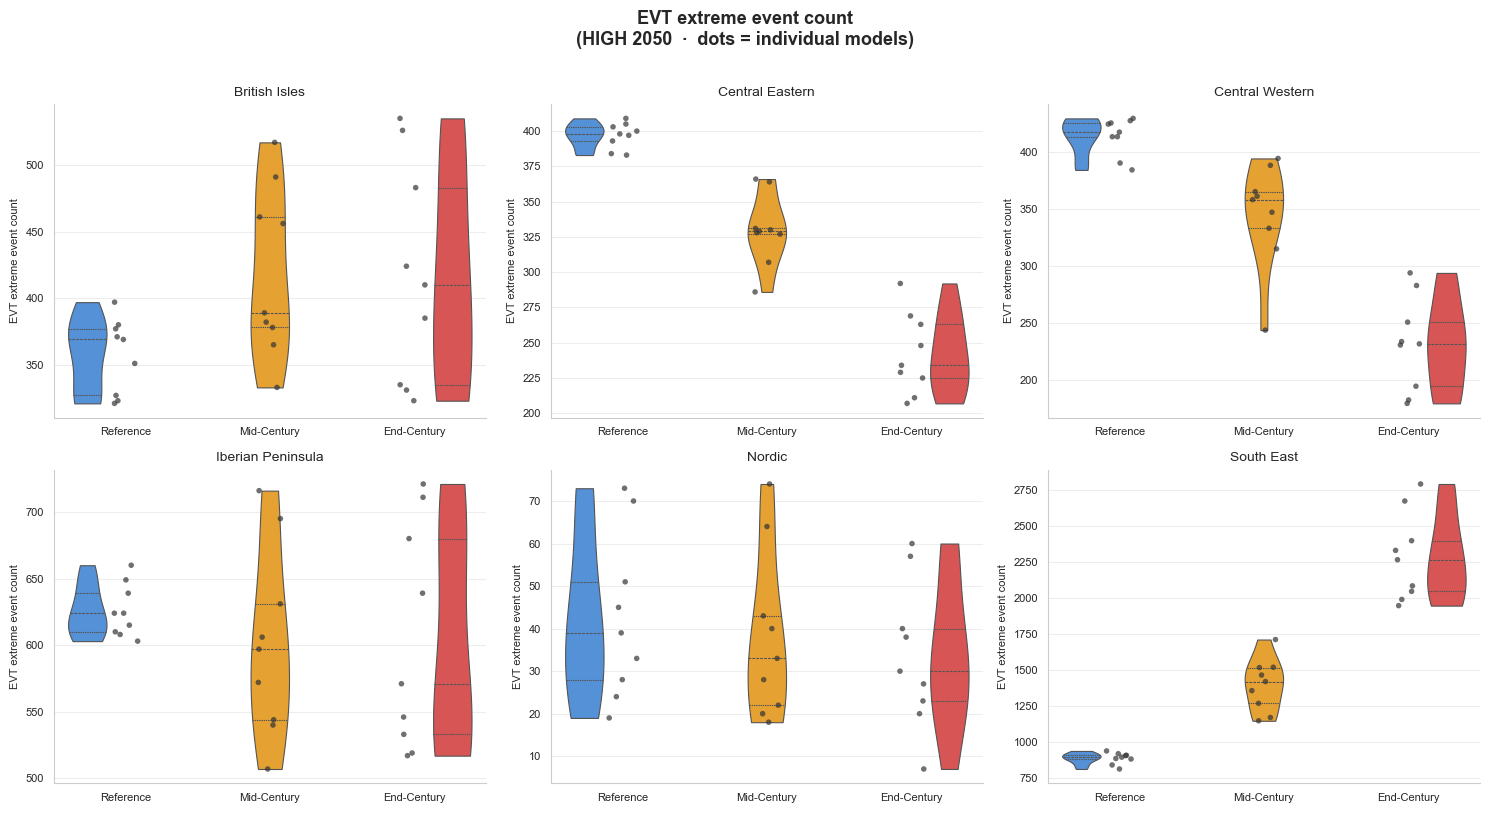

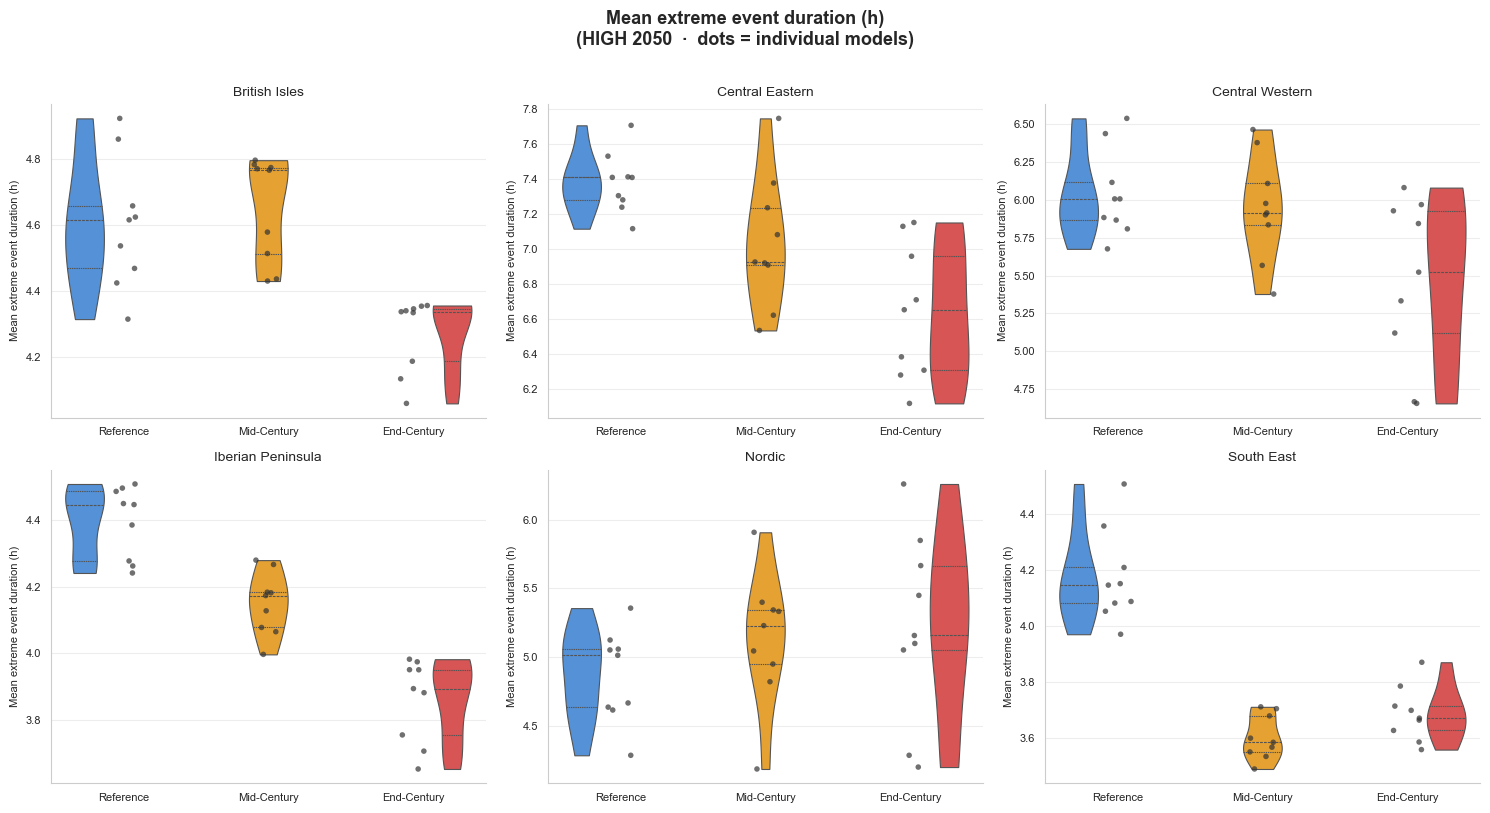

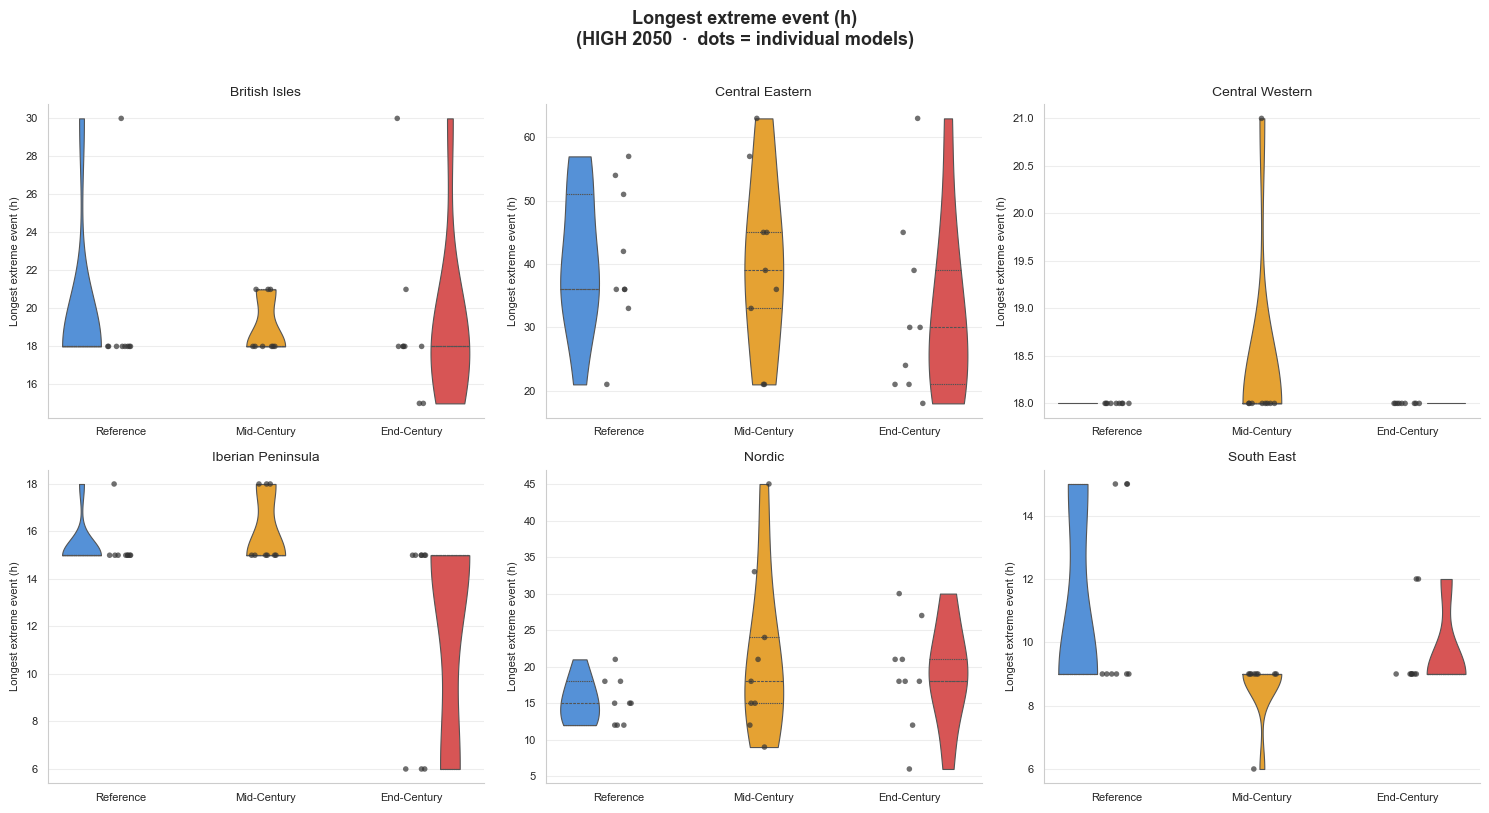

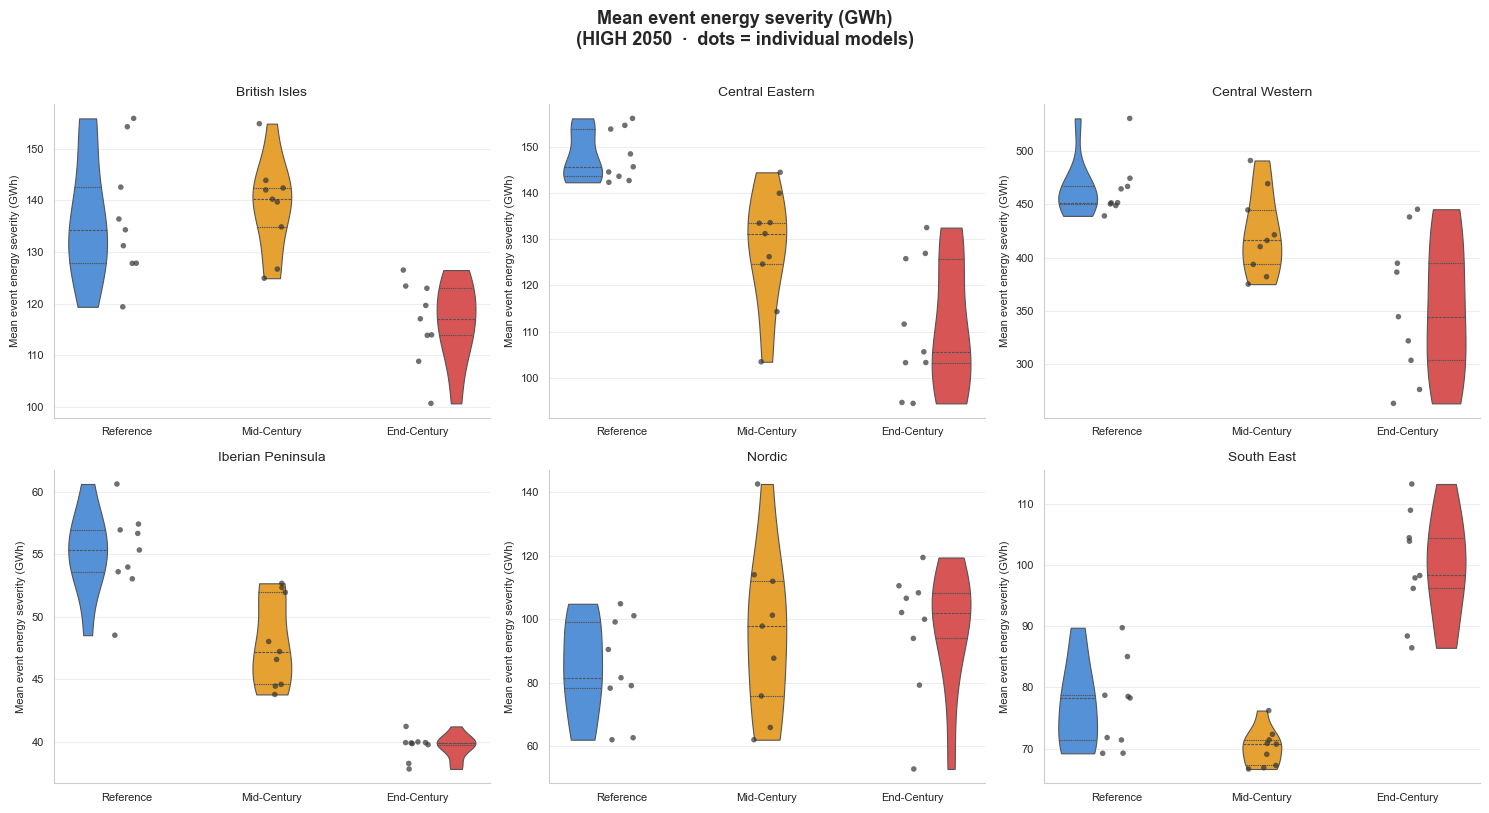

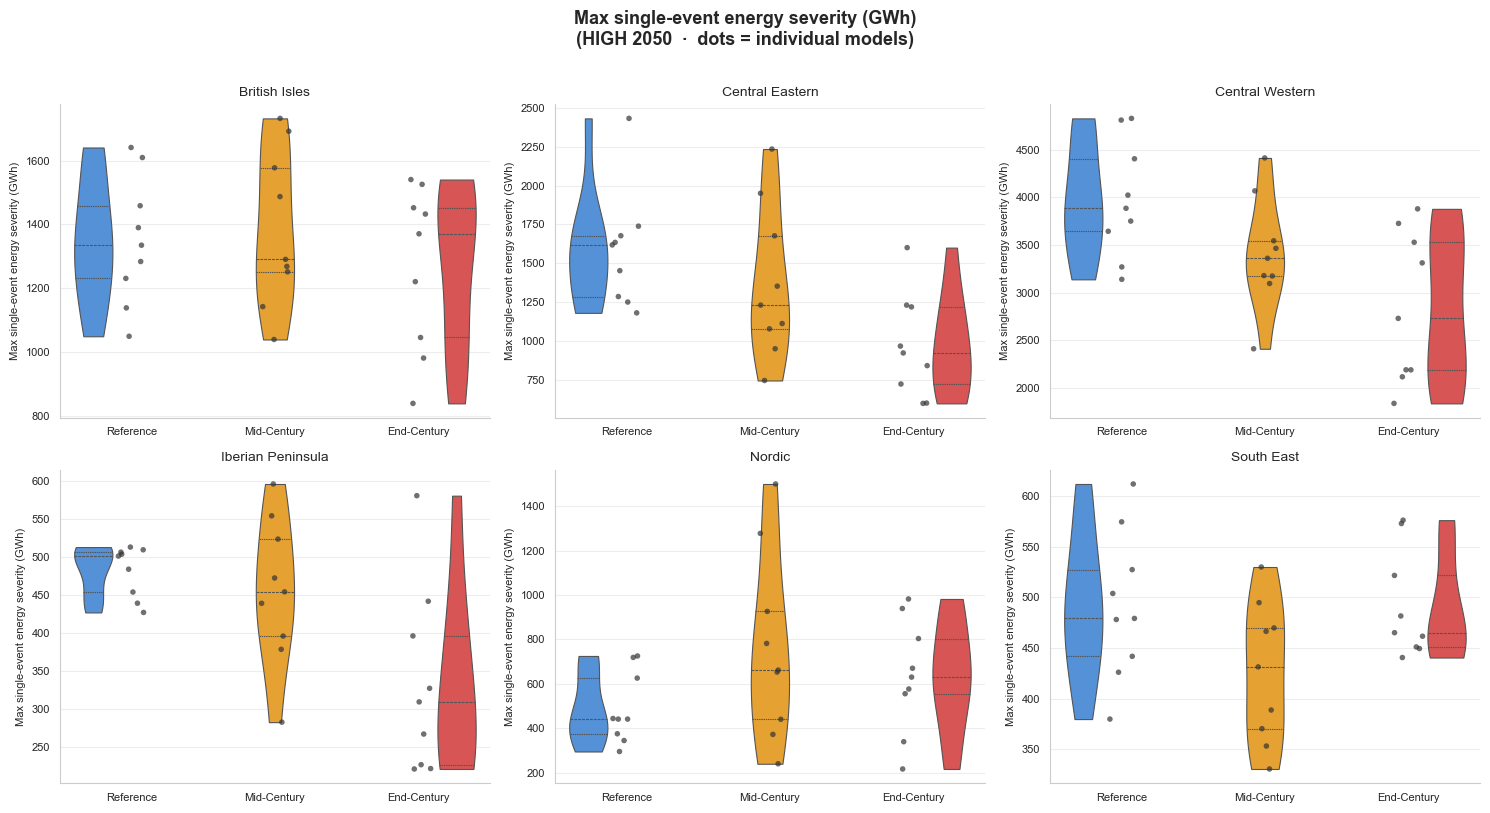

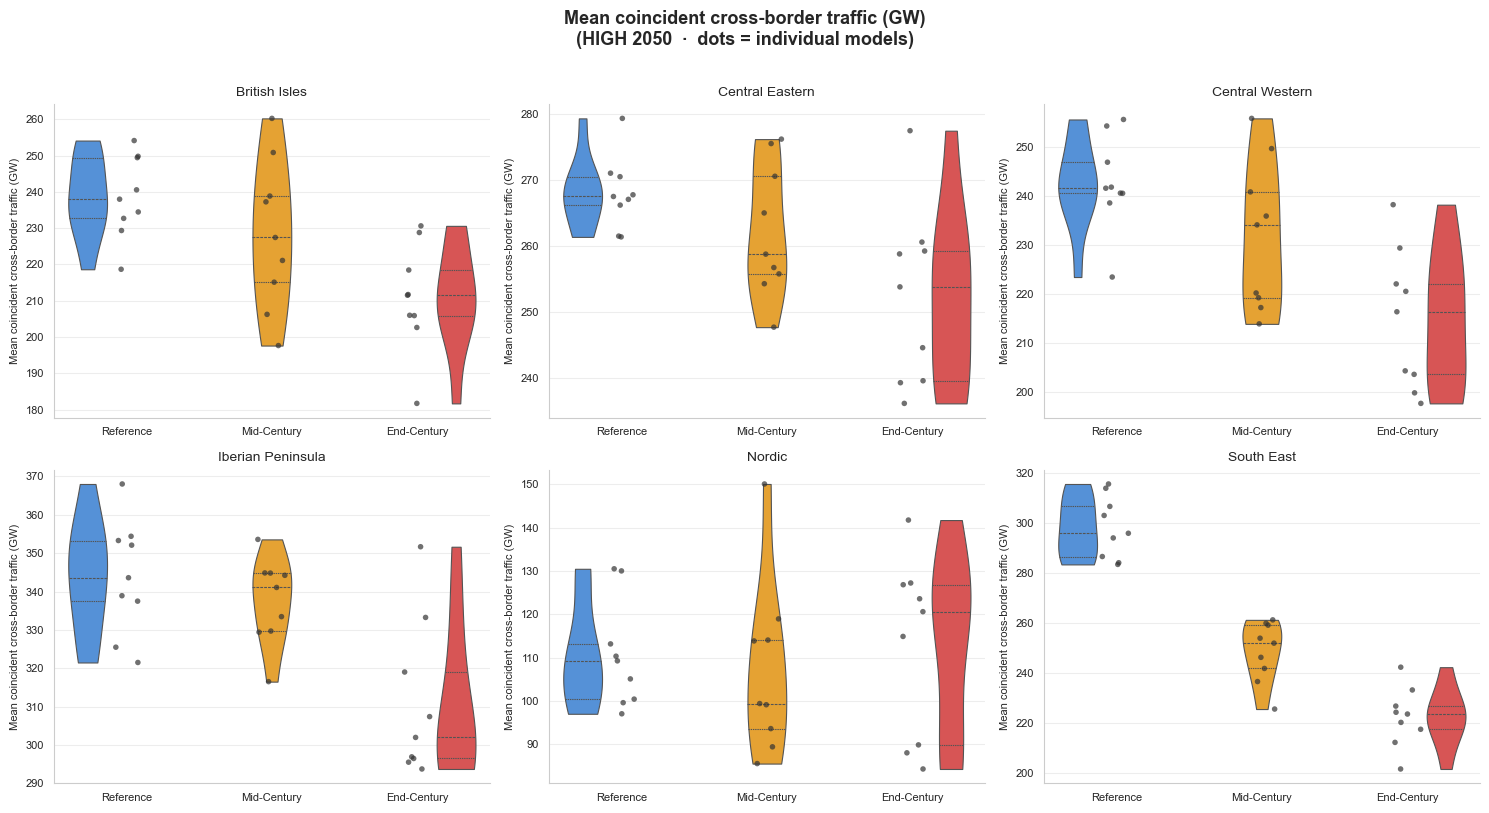

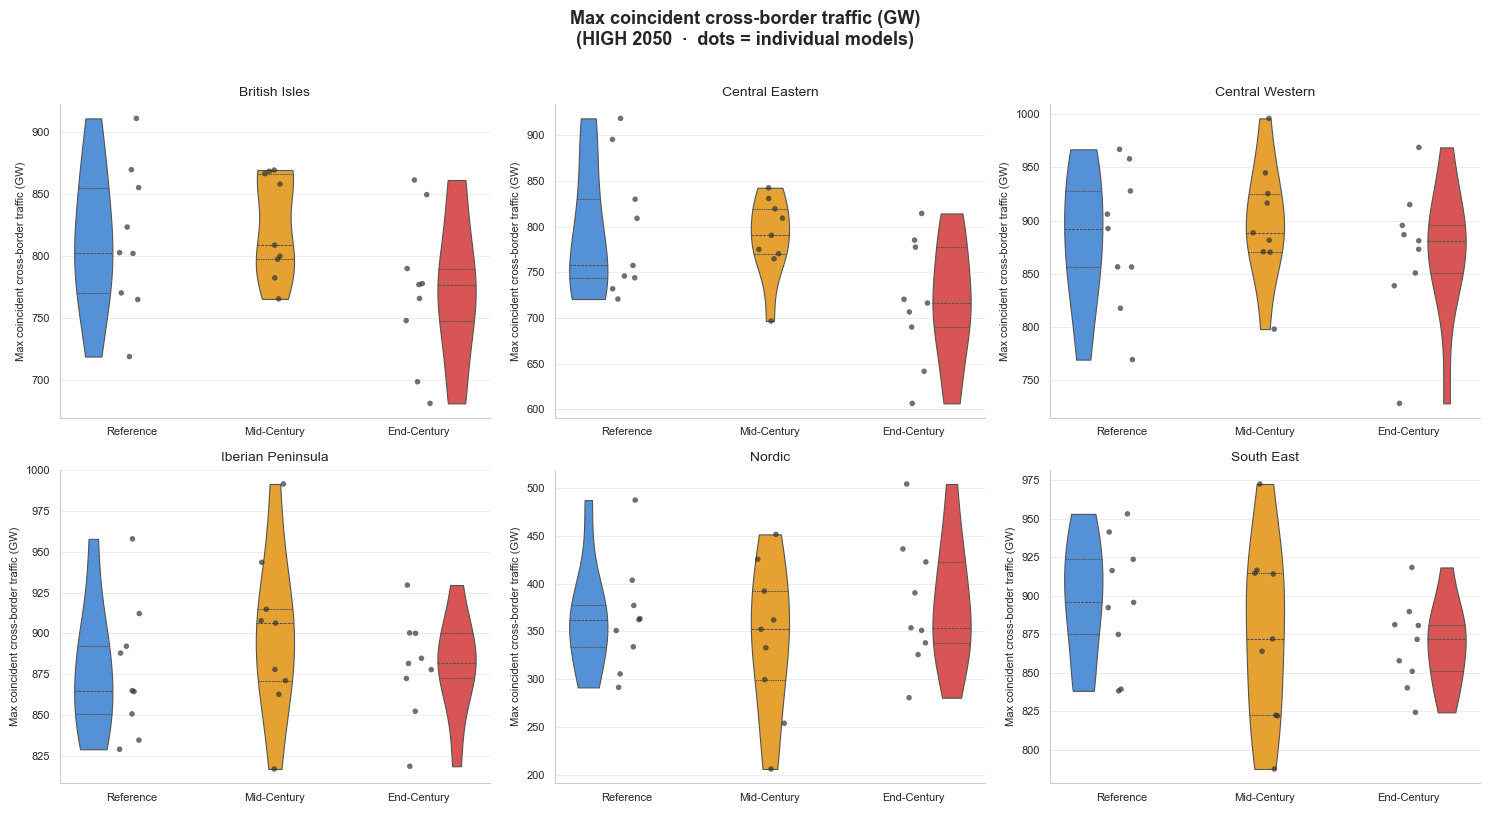

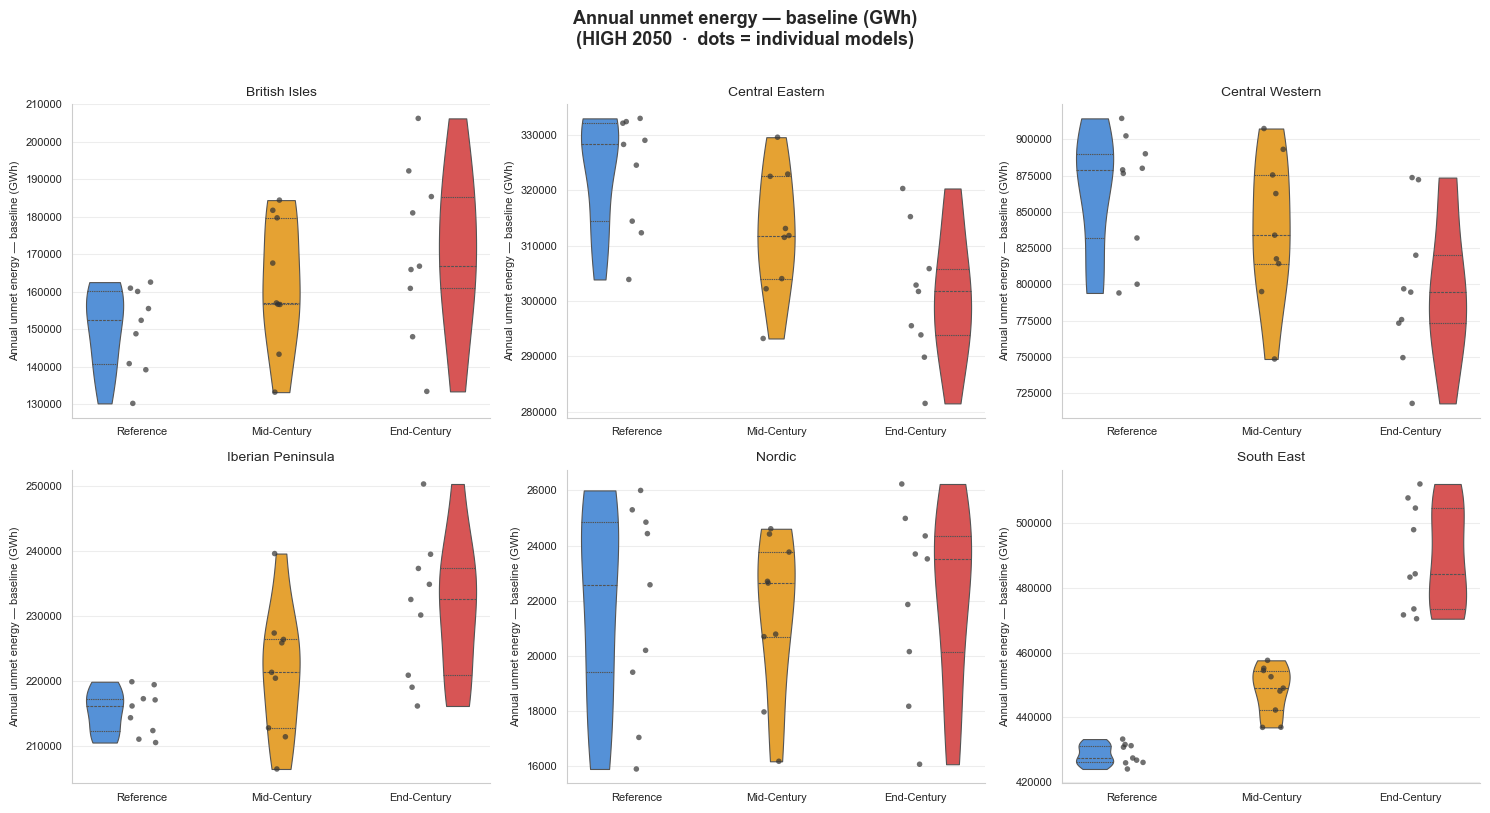

In [81]:
def _violin_grid(df_ens, metric, ylabel, title):
    """2×3 violin-plot grid: one violin per zone × period.

    Violins are coloured by period; individual model values are overlaid as
    strip-plot dots so the actual sample size is always visible.
    """
    period_order = list(period_defs.keys())
    vpal = [period_colors[p] for p in period_order]

    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=False)
    fig.suptitle(title, fontsize=13, fontweight="bold", y=1.01)

    for ax, zone in zip(axes.flatten(), zones):
        df_z = df_ens[df_ens["Zone"] == zone][["Period", metric]].copy()
        df_z["Period"] = pd.Categorical(
            df_z["Period"], categories=period_order, ordered=True
        )

        sns.violinplot(
            data=df_z,
            x="Period",
            y=metric,
            hue="Period",
            order=period_order,
            palette=vpal,
            ax=ax,
            inner="quartile",
            cut=0,
            linewidth=0.8,
            saturation=0.85,
            legend=False,
        )
        sns.stripplot(
            data=df_z,
            x="Period",
            y=metric,
            hue="Period",
            order=period_order,
            ax=ax,
            palette=["0.2"] * len(period_order),
            size=4,
            alpha=0.7,
            jitter=True,
            zorder=5,
            legend=False,
        )

        ax.set_title(zone.replace("_", " "), fontsize=10)
        ax.set_xlabel("")
        ax.set_ylabel(ylabel, fontsize=8)
        ax.tick_params(axis="x", labelsize=8)
        ax.tick_params(axis="y", labelsize=8)
        sns.despine(ax=ax)

    plt.tight_layout()
    plt.show()


violin_metrics = [
    ("Frequency", "EVT extreme event count", df_ens_extreme),
    ("Avg_Duration_Hours", "Mean extreme event duration (h)", df_ens_extreme),
    ("Max_Duration_Hours", "Longest extreme event (h)", df_ens_extreme),
    ("Avg_Energy_Severity_GWh", "Mean event energy severity (GWh)", df_ens_extreme),
    (
        "Max_Single_Event_Severity_GWh",
        "Max single-event energy severity (GWh)",
        df_ens_extreme,
    ),
    (
        "Avg_PCIT_During_Events_GW",
        "Mean coincident cross-border traffic (GW)",
        df_ens_extreme,
    ),
    (
        "Max_PCIT_During_Events_GW",
        "Max coincident cross-border traffic (GW)",
        df_ens_extreme,
    ),
    (
        "Total_Annual_Energy_Severity_GWh",
        "Annual unmet energy — baseline (GWh)",
        df_ens_baseline,
    ),
]

for metric, ylabel, df_ens in violin_metrics:
    _violin_grid(
        df_ens,
        metric,
        ylabel,
        title=f"{ylabel}\n({supply_scenario} {supply_year}  ·  dots = individual models)",
    )

In [82]:
(df_ens_baseline[df_ens_baseline["Period"] == "Mid-Century"].groupby("model")["Total_Annual_Energy_Severity_GWh"].sum() * 1e-3)

model
CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1          1839.400446
CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1                1952.046908
CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1               2051.768019
CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1                  1911.853120
MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1    1982.922262
MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1          2012.639618
MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1          2131.808906
MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1         2103.315500
MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1            2051.381688
Name: Total_Annual_Energy_Severity_GWh, dtype: float64

## EVT threshold heatmap — inter-model spread

The heatmap shows the model-specific EVT threshold calibrated on each model's
reference-period residual load. Rows are models; columns are zones.
Values in GWh (per 3-hour interval). Spread across rows indicates how much the
choice of model affects what is considered an "extreme" event.

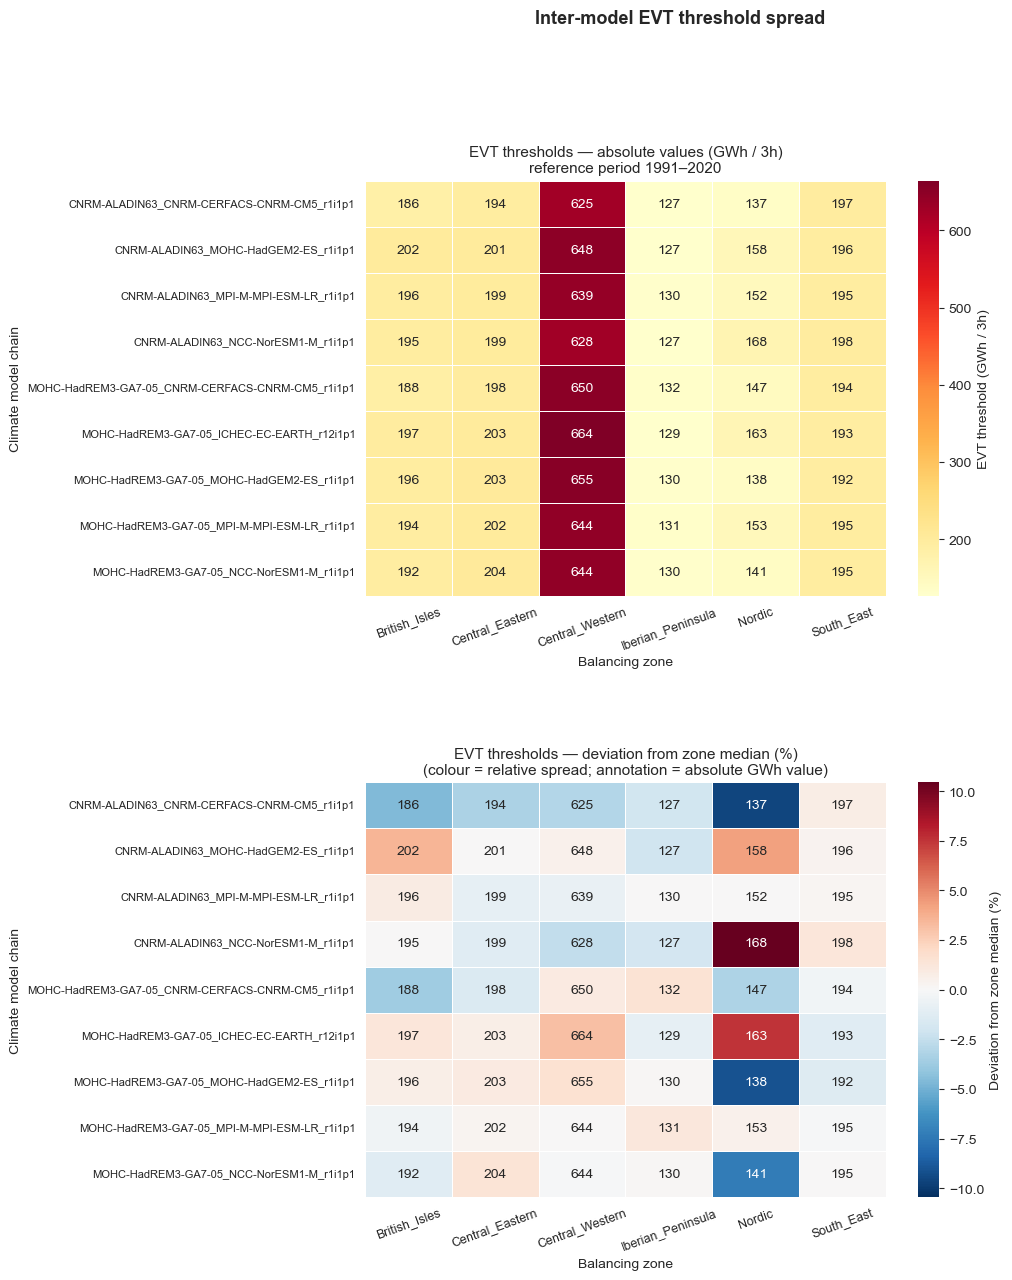


Zone medians (GWh):
Zone
British_Isles        194.7
Central_Eastern      201.1
Central_Western      644.3
Iberian_Peninsula    129.9
Nordic               151.8
South_East           195.0

Inter-model spread — IQR (GWh):
Zone
British_Isles         4.1
Central_Eastern       4.0
Central_Western      11.3
Iberian_Peninsula     2.7
Nordic               17.6
South_East            1.5

Inter-model spread — IQR / median (%):
Zone
British_Isles         2.1
Central_Eastern       2.0
Central_Western       1.7
Iberian_Peninsula     2.1
Nordic               11.6
South_East            0.8


In [83]:
# Build threshold matrix: rows = models, columns = zones
thr_matrix = pd.DataFrame(
    {
        model: {str(z): float(evt_thresholds[model].sel(zone=z).values) for z in zones}
        for model in models
    }
).T  # (n_models × n_zones)
thr_matrix.index.name = "Model"
thr_matrix.columns.name = "Zone"

# Percent deviation from the zone-median across models
# (removes the zone-level offset so inter-model spread is visible everywhere)
zone_medians = thr_matrix.median(axis=0)
thr_pct_dev = (thr_matrix - zone_medians) / zone_medians * 100

# ── Figure: two-panel (absolute + normalised) ─────────────────────────────────
fig, axes = plt.subplots(
    2,
    1,
    figsize=(max(8, len(zones) * 1.4), max(5, len(models) * 0.65) * 2 + 1.5),
    gridspec_kw={"hspace": 0.45},
)

# Panel 1 — absolute values (original view, kept for reference)
sns.heatmap(
    thr_matrix,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.4,
    linecolor="white",
    cbar_kws={"label": "EVT threshold (GWh / 3h)"},
    ax=axes[0],
)
axes[0].set_title(
    f"EVT thresholds — absolute values (GWh / 3h)\n"
    f"reference period {REFERENCE_PERIOD[0]}–{REFERENCE_PERIOD[1]}",
    fontsize=11,
)
axes[0].set_xlabel("Balancing zone", fontsize=10)
axes[0].set_ylabel("Climate model chain", fontsize=10)
axes[0].tick_params(axis="x", rotation=20, labelsize=9)
axes[0].tick_params(axis="y", rotation=0, labelsize=8)

# Panel 2 — percent deviation from zone median (highlights inter-model spread)
# Annotation = absolute value for context; colour = relative deviation
annot_abs = thr_matrix.map(lambda v: f"{v:.0f}")  # pandas ≥2.1: map replaces applymap
abs_limit = max(abs(thr_pct_dev.values.min()), abs(thr_pct_dev.values.max()))
abs_limit = max(abs_limit, 5)  # at least ±5 % so the colourbar isn't degenerate

sns.heatmap(
    thr_pct_dev,
    annot=annot_abs,
    fmt="",
    cmap="RdBu_r",
    center=0,
    vmin=-abs_limit,
    vmax=abs_limit,
    linewidths=0.4,
    linecolor="white",
    cbar_kws={"label": "Deviation from zone median (%)"},
    ax=axes[1],
)
axes[1].set_title(
    "EVT thresholds — deviation from zone median (%)\n"
    "(colour = relative spread; annotation = absolute GWh value)",
    fontsize=11,
)
axes[1].set_xlabel("Balancing zone", fontsize=10)
axes[1].set_ylabel("Climate model chain", fontsize=10)
axes[1].tick_params(axis="x", rotation=20, labelsize=9)
axes[1].tick_params(axis="y", rotation=0, labelsize=8)

plt.suptitle(
    "Inter-model EVT threshold spread",
    fontsize=13,
    fontweight="bold",
    y=1.01,
)
plt.show()

print("\nZone medians (GWh):")
print(zone_medians.round(1).to_string())
print("\nInter-model spread — IQR (GWh):")
iqr = thr_matrix.quantile(0.75) - thr_matrix.quantile(0.25)
print(iqr.round(1).to_string())
print("\nInter-model spread — IQR / median (%):")
print((iqr / zone_medians * 100).round(1).to_string())

## Climate driver attribution — ensemble view

Stacked-bar charts showing the **ensemble-median attribution** (share of extreme-event
energy anomaly attributable to each driver) for each zone and period.
Individual model values are overlaid as dots so disagreement is immediately visible.

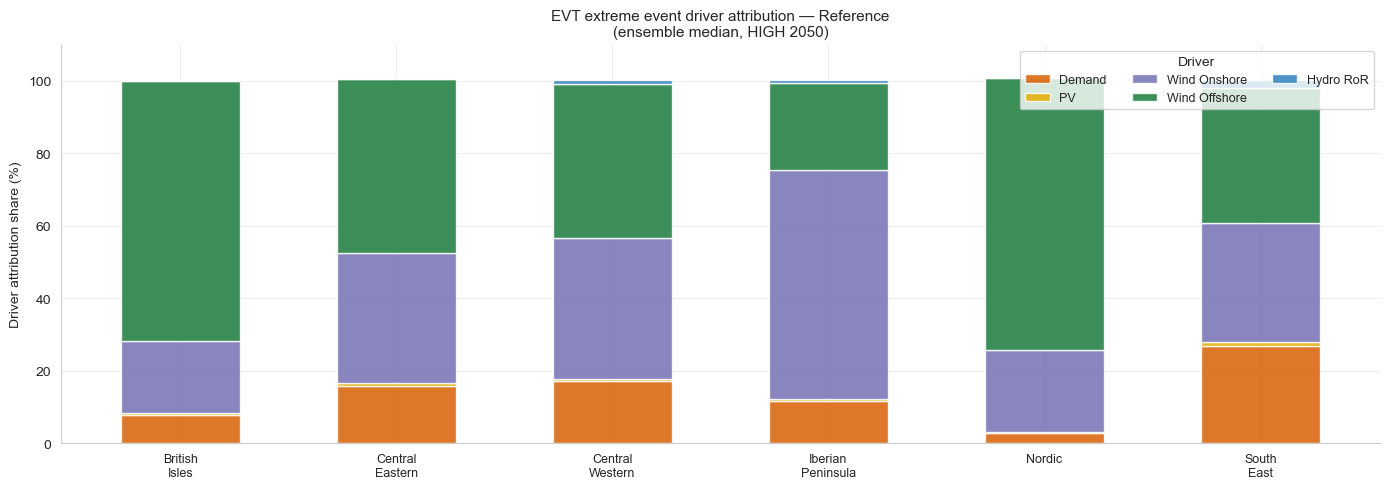

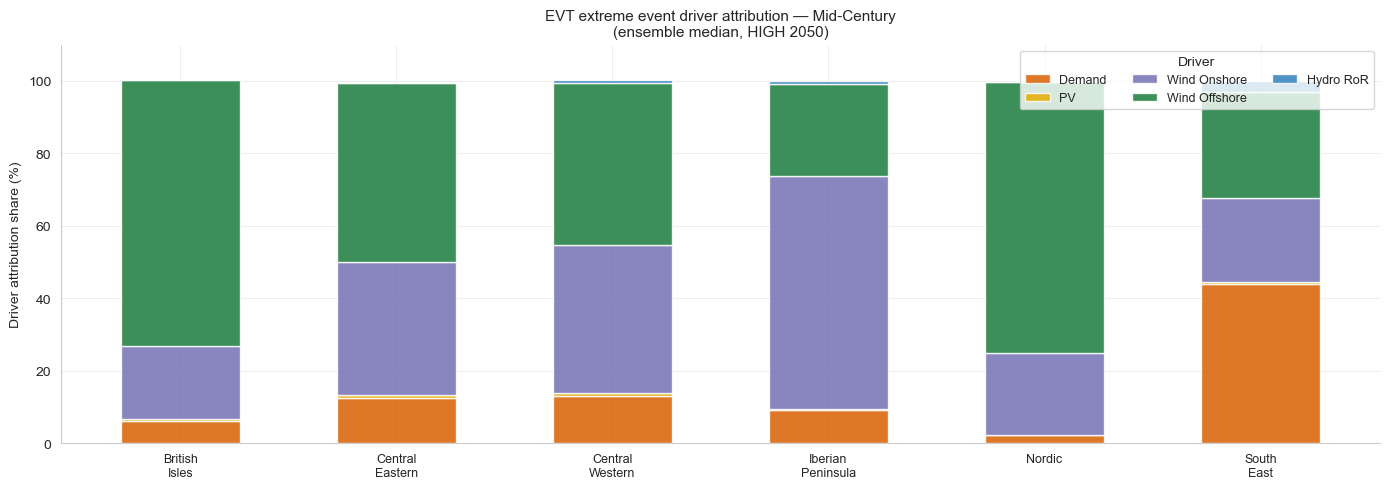

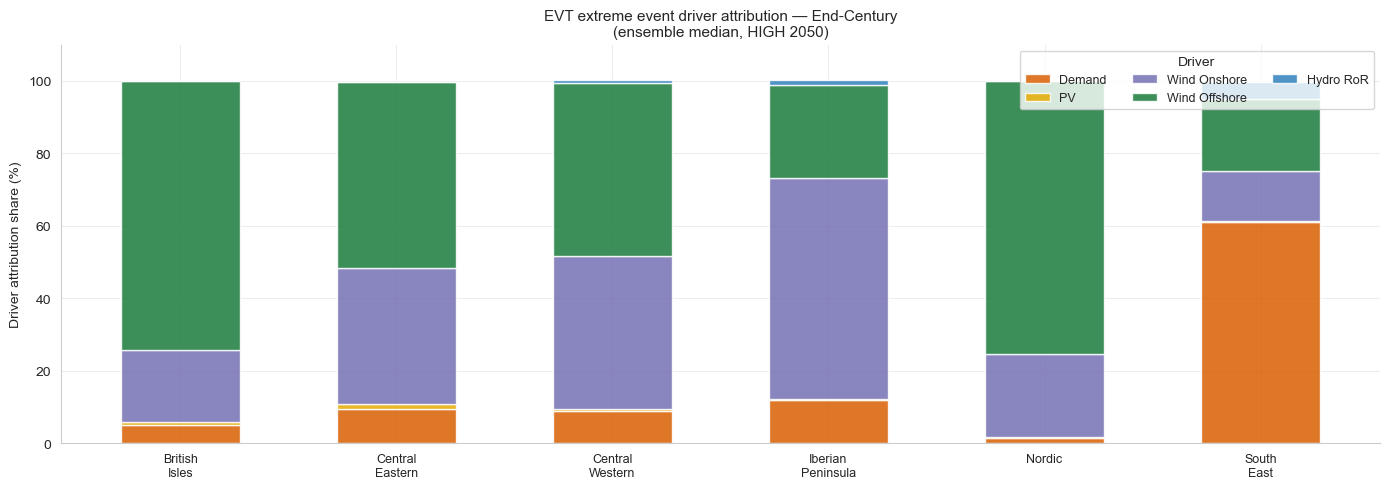

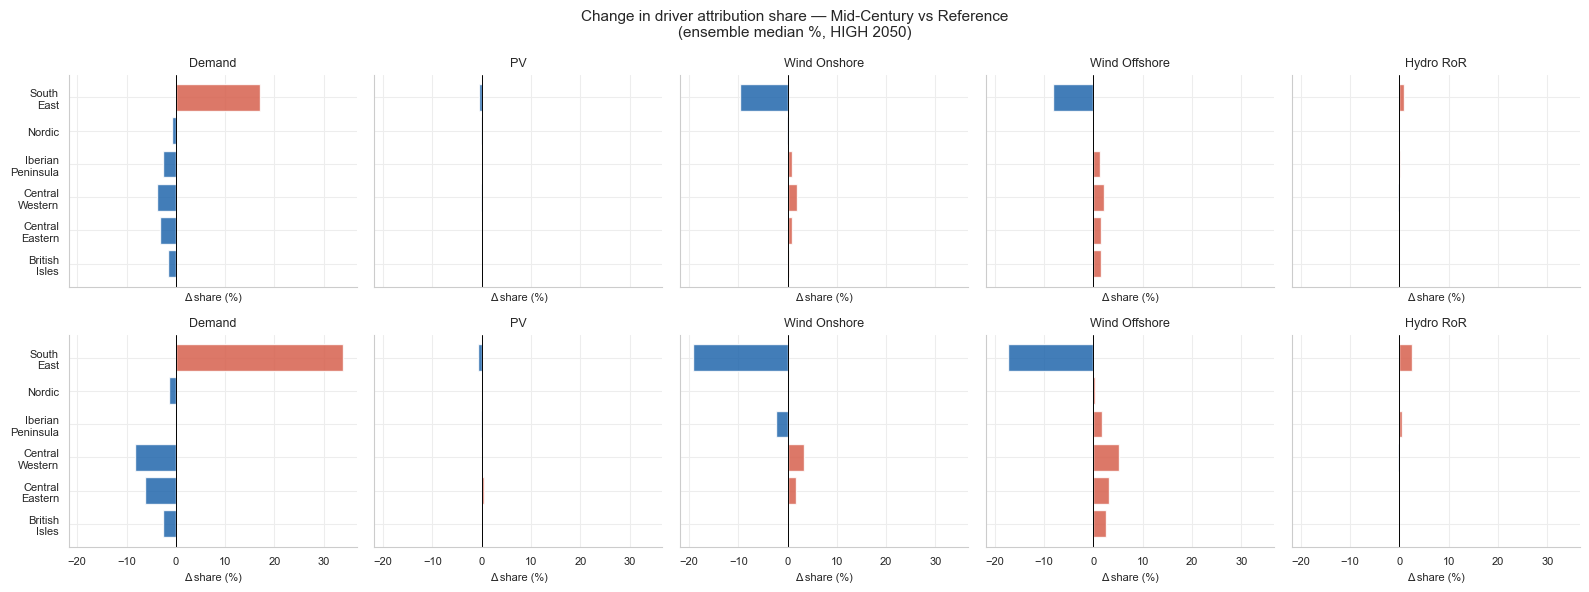

In [84]:
period_order = list(period_defs.keys())
n_zones = len(zones)
x_base = np.arange(n_zones)

for period_name in period_order:
    df_p = df_ens_extreme[df_ens_extreme["Period"] == period_name]

    fig, ax = plt.subplots(figsize=(14, 5))
    bottoms = np.zeros(n_zones)

    for driver, col in driver_cols.items():
        medians = [df_p[df_p["Zone"] == z][col].median() for z in zones]
        ax.bar(
            x_base,
            medians,
            bottom=bottoms,
            color=driver_palette[driver],
            label=driver,
            width=0.55,
            alpha=0.85,
        )
        bottoms += np.array(medians)

    ax.set_xticks(x_base)
    ax.set_xticklabels([z.replace("_", "\n") for z in zones], fontsize=9)
    ax.set_ylabel("Driver attribution share (%)", fontsize=10)
    ax.set_ylim(0, 110)
    ax.set_title(
        f"EVT extreme event driver attribution — {period_name}\n"
        f"(ensemble median, {supply_scenario} {supply_year})",
        fontsize=11,
    )
    ax.legend(loc="upper right", fontsize=9, ncol=3, title="Driver")
    sns.despine()
    plt.tight_layout()
    plt.show()


# ── Attribution change: heatmap of ΔShare (Mid-Century − Reference) ──────────
fig, axes = plt.subplots(2, len(driver_cols), figsize=(16, 6), sharey=True, sharex=True)
fig.suptitle(
    f"Change in driver attribution share — Mid-Century vs Reference\n"
    f"(ensemble median %, {supply_scenario} {supply_year})",
    fontsize=11,
)

for ax, (driver, col) in zip(axes[0], driver_cols.items()):
    ref_vals = (
        df_ens_extreme[df_ens_extreme["Period"] == "Reference"]
        .groupby("Zone")[col]
        .median()
    )
    mid_vals = (
        df_ens_extreme[df_ens_extreme["Period"] == "Mid-Century"]
        .groupby("Zone")[col]
        .median()
    )
    delta = (mid_vals - ref_vals).reindex(zones)

    colors = ["#2166AC" if v <= 0 else "#D6604D" for v in delta.values]
    ax.barh(range(len(zones)), delta.values, color=colors, alpha=0.85)
    ax.axvline(0, color="black", lw=0.7)
    ax.set_title(driver, fontsize=9)
    ax.set_xlabel("Δ share (%)", fontsize=8)
    ax.set_yticks(range(len(zones)))
    ax.set_yticklabels([z.replace("_", "\n") for z in zones], fontsize=7)
    ax.tick_params(labelsize=8)
    sns.despine(ax=ax)

# # ── Attribution change: heatmap of ΔShare (End-Century − Reference) ──────────
# fig, axes = plt.subplots(, len(driver_cols), figsize=(16, 4), sharey=True)
# fig.suptitle(
#     f"Change in driver attribution share — End-Century vs Reference\n"
#     f"(ensemble median %, {supply_scenario} {supply_year})",
#     fontsize=11,
# )

for ax, (driver, col) in zip(axes[1], driver_cols.items()):
    ref_vals = (
        df_ens_extreme[df_ens_extreme["Period"] == "Reference"]
        .groupby("Zone")[col]
        .median()
    )
    end_vals = (
        df_ens_extreme[df_ens_extreme["Period"] == "End-Century"]
        .groupby("Zone")[col]
        .median()
    )
    delta = (end_vals - ref_vals).reindex(zones)

    colors = ["#2166AC" if v <= 0 else "#D6604D" for v in delta.values]
    ax.barh(range(len(zones)), delta.values, color=colors, alpha=0.85)
    ax.axvline(0, color="black", lw=0.7)
    ax.set_title(driver, fontsize=9)
    ax.set_xlabel("Δ share (%)", fontsize=8)
    ax.set_yticks(range(len(zones)))
    ax.set_yticklabels([z.replace("_", "\n") for z in zones], fontsize=7)
    ax.tick_params(labelsize=8)
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()